# סיווג משלחי יד מנתוני סקר
**מטלת קבלה לתפקיד מדען נתונים בכיר · Or Shulrufer**

כדי להדגים תהליך שניתן לבדוק ולהריץ מחדש, המחברת עוברת מהגדרת המשימה ומהנתונים המקוריים אל השוואת פתרונות ותחזיות. הדגש הוא על החלטות נכונות וקריאות הקוד. הנתונים סינתטיים, והמטלה מציינת שאין משמעות לציון החיזוי לצורך ההערכה.

[הקוד ב-GitHub](https://github.com/shulruferor-sudo/Advance-Data-Science/blob/main/project_notebooks/survey/survey_complete.ipynb) · [פתיחה ב-Google Colab](https://colab.research.google.com/github/shulruferor-sudo/Advance-Data-Science/blob/main/project_notebooks/survey/survey_complete.ipynb)

**הרצה:** Runtime → Run all, במעבד CPU. קובץ המקור כלול במחברת בתא מכווץ, עם בדיקת שלמות. הנתונים זמינים גם ללא חיבור ל-Drive או SSH. במאגר פרטי אפשר להוריד את המחברת ולהעלות אותה ל-Colab. זמן ההרצה בפועל נמדד ומוצג. אין צורך ב-GPU.

**התוצר:** הגדרות וטיפול בכל 18 העמודות, תרשימים משולבים, כל תוצאות המועמדים שנבדקו, תחזיות בדיקה, הצעות לקודים חלקיים וקובצי תוצאות. מצגת בת עשרה שקפים מסכמת את אותו תהליך.

[מצגת PowerPoint](https://github.com/shulruferor-sudo/Advance-Data-Science/blob/main/project_notebooks/survey/survey_presentation.pptx) · [מצגת PDF](https://github.com/shulruferor-sudo/Advance-Data-Science/blob/main/project_notebooks/survey/survey_presentation.pdf)

## 1. מתחילים מהחלטה עסקית שניתן לתמוך בה
כדי לבנות את תהליך הסיווג האוטומטי המבוקש, נלמד לחזות את משלח היד של נסקר לפי התשובות הזמינות בעת קבלת שאלון חדש. היעד העסקי הוא ביצוע עבודת הסימול האוטומטית לכל שאלון מתאים. סיוע לסמלן הוא שלב הטמעה מוצע, ולא צמצום המשימה לרשומות עם X. `SemelMishlachSofi` הוא יעד רב-מחלקתי נומינלי: אין משמעות לחיסור בין שני קודים. התוצר הראשון הוא הצעת סימול. הפעלה אוטומטית תדרוש בהמשך מדידת טעויות וכיסוי על נתוני אמת מאומתים.

שלוש הבחנות מנחות את המימוש:

| מצב במטלה | ההחלטה והנימוק | מה אין בקובץ כדי להכריע יותר |
|---|---|---|
| שאלון חלקי ושידורים חוזרים | שומרים תשובות חסרות. לא ממזגים שורות ולא בוחרים "אחרונה" לפי מספר רץ | מזהה נסקר יציב, מזהה שידור וחותמת זמן לשידור |
| סימול ידני בכ-90% נכונות ו-`X` | קוד חלקי אינו מקצוע חדש. לומדים מקודים מלאים, מפיקים הצעות לחלקיים ומדווחים סתירות | אמת מקצועית מאומתת ומזהה סמלן. אי אפשר לזהות בדיוק 10% תוויות שגויות |
| שדות בעלי משמעות ותזמון שונים | משתמשים במשמעות שב-Metadata. בודקים תנאי מילוי וזמינות בזמן החיזוי | האם קוד הענף הסופי זמין לפני סימול משלח היד. תאריך הסקר לצורך חישוב ותק |

הניתוב האקראי לסמלנים אינו מבטיח שאין טעויות שיטתיות ואינו פותר את החוסר במזהה סמלן. שיעור ה-90% אינו תקרת דיוק של מודל מול אמת מקצועית. חסר מותר אינו בהכרח שגיאת נתונים. קוד מלא אינו בהכרח קוד נכון.

### שני הקודים מתארים שני מושגים שונים
כדי להגדיר נכון מה לומדים ומה חוזים, קוראים את ההגדרות המפורשות ב-Metadata:

| שדה | מה הוא מתאר | תפקיד בניסוי |
|---|---|---|
| `SemelAnafSofi` | הענף הכלכלי של מקום העבודה | מידע לביקורת. זמינותו לפני סימול משלח היד אינה מתועדת |
| `SemelMishlachSofi` | משלח היד של האדם | יעד הסיווג שהמטלה מציינת במפורש |

אלה קודים נומינליים, ולא כמויות או עמודות נפרדות לאימון ולחיזוי. שני השדות מוגדרים כ-TEXT של ארבע ספרות. המטלה אינה מגדירה היררכיה של ספרות, לכן אין חיסור בין קודים, רגרסיה על הקוד או הסקת קבוצות מקצוע מהקידומת. קידוד פנימי של תוויות עבור ספרייה הוא מיפוי שמות בלבד, שמוחזר לקוד המקורי בחיזוי.

האות X מופיעה בתשע רשומות בענף הכלכלי ובתשע רשומות אחרות במשלח היד. רשומה 5 כוללת ענף `XXXX` ומשלח יד `5322`, ולכן יש לה יעד מלא והיא נשמרת בלמידה. רשומה 18 כוללת ענף `8411` ומשלח יד `1XXX`, ולכן אין לה יעד מלא לאימון מפוקח. מסננים לפי שלמות **משתנה המטרה בלבד**. כך נשמרות 191 תוויות מלאות ותשע רשומות ליישום נפרד. אף אחד משני קודי התוצאה אינו מאפיין חיזוי.

הסימול הידני המלא מספק תוויות לאימון ולבדיקה. רשומות X הן הדגמת יישום שימושית, ולא כל אוכלוסיית היעד של המערכת. חיזוי חוזר של רשומה שכבר סומלה יכול לשמש לביקורת, אך אי-הסכמה עם אדם אינה הוכחה שהאדם טעה. המקור קובע במפורש שסימולי משלח היד ניתנו ידנית. תהליך יצירת קוד הענף ותזמונו אינם מפורטים.


## 2. סביבת ריצה קבועה מאפשרת לשחזר את העבודה
כדי שהמחברת תפעל ב-Colab עם אותו ממשק מודלים, מתקינים לפני הייבוא רק גרסאות חסרות או שונות של התלויות המפורשות. משתמשים בספריות המקובלות של Python ובמימושים הקיימים של scikit-learn. בסיום התא מתקבלת סביבת ריצה מזוהה ותיקייה לתוצאות המחושבות בהרצה זו.

In [1]:
import importlib.metadata
import subprocess
import sys

for package, version in {'scikit-learn': '1.8.0', 'openpyxl': '3.1.5',
                         'xgboost': '3.0.5', 'lightgbm': '4.6.0', 'catboost': '1.2.10'}.items():
    try:
        installed_version = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        installed_version = None
    if installed_version != version:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', f'{package}=={version}'])

import base64
import gzip
import hashlib
import io
import json
import re
import tempfile
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, VotingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score, make_scorer, calinski_harabasz_score
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit, KFold, cross_val_predict
from sklearn.naive_bayes import ComplementNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits

RANDOM_SEED = 42
TARGET_FIELD = 'SemelMishlachSofi'
OUTPUT_DIRECTORY = Path('survey_results')
OUTPUT_DIRECTORY.mkdir(exist_ok=True)
threadpool_limits(limits=1)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_columns', None)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
run_started = time.perf_counter()
print({'python': sys.version.split()[0], 'pandas': pd.__version__, 'scikit_learn': sklearn.__version__})

{'python': '3.12.14', 'pandas': '2.2.3', 'scikit_learn': '1.8.0'}


## 3. גבולות טבלת המקור קודמים לניקוי
כדי שלא נלמד מתאים שאינם רשומות סקר, טוענים את שני הגיליונות ומגבילים את הקריאה לאזורי הטבלה שנבדקו בקובץ. גיליון Metadata מכיל 18 הגדרות בארבע עמודות. בהמשך השורה האחרונה מופיע השם `TarichHathala` פעמים רבות ללא הגדרות חדשות. בגיליון הסקר יש 200 רשומות, ואחריהן רק התא `J202` עם הנוסחה `=1.5*1.15`. זו אינה רשומת סקר וגם אינה ממוצע של הנתונים.

הקוד שומר את ערכי המקור בנפרד ומציג את האזור שהוחרג. שמות השדות מחברים בין הטבלאות, משום שסדרם שונה. התוצאה היא טבלת רשומות וטבלת הגדרות שניתן להצליב בלי לשנות את המקור. העותק מ-Drive זהה בבייטים לעותק הנתונים במאגר בעת האיסוף.

In [2]:
#@title קובץ ה-Excel המקורי וטעינת שני הגיליונות
SOURCE_WORKBOOK_GZIP = '...'
source_bytes = gzip.decompress(base64.b64decode(SOURCE_WORKBOOK_GZIP))
SOURCE_SHA256 = 'e1e7f391c0675dd14830eaae6b5cd114edc256f18b956bb48a454b0b1209e1ac'
assert hashlib.sha256(source_bytes).hexdigest() == SOURCE_SHA256
workbook = pd.ExcelFile(io.BytesIO(source_bytes), engine='openpyxl')
assert set(workbook.sheet_names) == {'Survey Dataset', 'Metadata'}
metadata = pd.read_excel(workbook, sheet_name='Metadata', usecols='A:D').dropna(subset=['משתנה'])
metadata[['משתנה', 'פורמט']] = metadata[['משתנה', 'פורמט']].apply(lambda column: column.str.strip())
field_definitions = metadata.set_index('משתנה', verify_integrity=True)
source_sheet = pd.read_excel(workbook, sheet_name='Survey Dataset', usecols='A:R', dtype=object)
excluded_cells = source_sheet.loc[source_sheet.ID.isna()].dropna(how='all')
survey_records = source_sheet.loc[source_sheet.ID.notna()].copy().reset_index(drop=True)
assert survey_records.shape == (200, 18) and metadata.shape == (18, 4)
assert survey_records.ID.is_unique and set(survey_records) == set(field_definitions.index)
assert excluded_cells.count().sum() == 1 and np.isclose(excluded_cells.MenahelEtMi.iloc[0], 1.725)
survey_records['ID'] = survey_records.ID.astype('int64')
for field in ['SemelAnafSofi', TARGET_FIELD]:
    survey_records[field] = survey_records[field].astype('string').str.strip().str.upper()
print('Survey records:', len(survey_records), '| Fields:', len(field_definitions))
display(metadata)
display(excluded_cells.dropna(axis=1, how='all'))

Survey records: 200 | Fields: 18


,משתנה,הסבר,פורמט,ערכים אפשריים
0,ID,מספר רץ,INTEGER,NaN
1,YeshuvAvoda,שם יישוב עבודה,TEXT,NaN
2,ShemAvoda,שם מקום העבודה שלך,TEXT,NaN
3,SugAvoda,הפעילות העיקרית של מקום העבודה,TEXT,NaN
4,ShemMachlaka,אגף או מחלקה שהנסקר עובד,TEXT,NaN
5,SugMachlaka,הפעילות העיקרית של האגף או המחלקה שהנסקר עובד,TEXT,NaN
6,EzoAvoda,עבודה שהנסקר עושה במקום עבודה זה,TEXT,NaN
7,TeurPeula,הפעולות העיקריות שהנסקר עושה במקום עבודה,TEXT,NaN
8,TeurTafkid,מהו תואר המשרה של הנסקר במקום עבודה זה (במידה ויש),TEXT,NaN
9,MenahelEtMi,האם הנסקר מנהל או ממונה על עובדים אחרים?,INTEGER,1. מנהל עובדים\n2. מנהל מנהלים\n3. מנהל עובדים ומנהלים


,MenahelEtMi
200,1.725


## 4. משמעות כל עמודה מגדירה את הטיפול
כדי לנצל את המידע בלי לייחס לקודים משמעות מספרית שגויה, מפרידים בין טקסט, קטגוריה וכמות. שם מעסיק ויישוב עשויים לספק הקשר, לכן אינם נפסלים מראש: הם נכללים בשני המסלולים תחת אותה מדיניות מאפיינים, והסיכון להסתמכות עליהם נרשם להמשך בדיקה על נתוני אמת. תאריך התחלה מספק כאן שנת התחלה בלבד, ולא ותק או סדר שידורים.

שלושה שדות אינם מאפייני חיזוי: היעד עצמו, המספר הרץ, וקוד הענף הסופי שזמינותו בזמן החיזוי אינה מתועדת. הבחירה האחרונה היא הנחת תכנון שמרנית, ולא קביעה שקוד הענף בהכרח דולף. הטבלה מציגה את ההגדרה, הנוכחות והחלטת הטיפול לכל 18 העמודות. היא משמשת חוזה לקלט המודל.

In [3]:
FIELD_DECISIONS = {'ID': ('identifier', 'מספר רץ לבדיקת שלמות ולחיבור תחזיות. אינו מזהה נסקר לאורך זמן.'),
 'YeshuvAvoda': ('category',
                 'יישוב העבודה: קטגוריה נומינלית. וריאציות כתיב נשמרות, ויישוב חדש מטופל כקטגוריה לא מוכרת.'),
 'ShemAvoda': ('category',
               'שם מקום העבודה: ישות נומינלית ב-One-hot. זהו שדה פתוח שיכול לכלול גם תיאור כללי. זמינות שם '
               'חדש מגבילה את One-hot.'),
 'SugAvoda': ('text', 'פעילות מקום העבודה: נשמרת בנפרד מעבודת הנסקר.'),
 'ShemMachlaka': ('text', 'שם המחלקה: ערוץ טקסט נפרד עם מצב חסר מפורש.'),
 'SugMachlaka': ('text', 'פעילות המחלקה: לא משלימים כנ״ל ללא יעד הפניה מתועד.'),
 'EzoAvoda': ('text', 'העבודה שהנסקר מבצע: ראיה ישירה למשלח היד. נשמרים עברית ואנגלית.'),
 'TeurPeula': ('text', 'פעולות עיקריות: נשמרות גם כשהשדה חסר ברוב השורות.'),
 'TeurTafkid': ('text', 'תואר משרה אם קיים: 0 הוא ערך לא מתועד, ולא מקצוע.'),
 'MenahelEtMi': ('category', 'שלוש קטגוריות ניהול. חסר אינו הוכחה שהאדם אינו מנהל.'),
 'MaamadAvoda': ('category', 'מעמד עבודה: שבע קטגוריות, ללא מרחק מספרי ביניהן.'),
 'MakorSachar': ('category', 'חל רק במעמד 1 או 5. מפרידים לא חל, חסר ותחולה לא ידועה.'),
 'TeudaGvoha': ('category', 'תעודה גבוהה: הקודים 8 ו-9 אינם המשך של סולם כמותי. One-hot.'),
 'shnotlimud': ('numeric', 'שנות לימוד: כמות, השלמת חציון וקנה מידה נלמדים באימון בלבד.'),
 'Gil': ('numeric', 'גיל: כמות זמינה בשאלון. יש לבדוק בהמשך אם תרומתו יציבה על נתונים אמיתיים.'),
 'TarichHathala': ('date', 'תאריך התחלת העבודה: המרה לשנה. אין חישוב ותק בלי תאריך סקר.'),
 'SemelAnafSofi': ('audit', 'קוד ענף סופי: נשמר לביקורת. חמישה קודים קצרים אינם מתוקנים אוטומטית.'),
 'SemelMishlachSofi': ('target', 'קוד יעד נומינלי. קודים מלאים לאימון. X להצעות נפרדות ובדיקת סמלן.')}
TEXT_FIELDS = [field for field, (role, _) in FIELD_DECISIONS.items() if role == 'text']
DESCRIPTION_FIELDS = TEXT_FIELDS.copy()
CATEGORY_FIELDS = [field for field, (role, _) in FIELD_DECISIONS.items() if role == 'category']
NUMBER_FIELDS = ['shnotlimud', 'Gil', 'start_year']
INPUT_FIELDS = [field for field, (role, _) in FIELD_DECISIONS.items()
                if role in ['text', 'category', 'numeric', 'date']]
allowed_codes = {field: set(map(int, re.findall(r'(?m)^\s*(\d+)\.', str(definition))))
                 for field, definition in field_definitions['ערכים אפשריים'].items()}
column_overview = pd.DataFrame({
    'definition': field_definitions['הסבר'], 'source_format': field_definitions['פורמט'],
    'missing': survey_records.isna().sum(), 'distinct': survey_records.nunique(),
    'role': {field: decision[0] for field, decision in FIELD_DECISIONS.items()},
    'treatment': {field: decision[1] for field, decision in FIELD_DECISIONS.items()}
}).reindex(survey_records.columns).rename_axis('field')
assert set(FIELD_DECISIONS) == set(survey_records)
display(column_overview)

,definition,source_format,missing,distinct,role,treatment
field,,,,,,
ID,מספר רץ,INTEGER,0,200,identifier,מספר רץ לבדיקת שלמות ולחיבור תחזיות. אינו מזהה נסקר לאורך זמן.
YeshuvAvoda,שם יישוב עבודה,TEXT,0,21,category,"יישוב העבודה: קטגוריה נומינלית. וריאציות כתיב נשמרות, ויישוב חדש מטופל כקטגוריה לא מוכרת."
ShemAvoda,שם מקום העבודה שלך,TEXT,0,82,category,שם מקום העבודה: ישות נומינלית ב-One-hot. זהו שדה פתוח שיכול לכלול גם תיאור כללי. זמינות שם חדש מ...
SugAvoda,הפעילות העיקרית של מקום העבודה,TEXT,25,78,text,פעילות מקום העבודה: נשמרת בנפרד מעבודת הנסקר.
ShemMachlaka,אגף או מחלקה שהנסקר עובד,TEXT,64,61,text,שם המחלקה: ערוץ טקסט נפרד עם מצב חסר מפורש.
SugMachlaka,הפעילות העיקרית של האגף או המחלקה שהנסקר עובד,TEXT,134,35,text,פעילות המחלקה: לא משלימים כנ״ל ללא יעד הפניה מתועד.
EzoAvoda,עבודה שהנסקר עושה במקום עבודה זה,TEXT,7,84,text,העבודה שהנסקר מבצע: ראיה ישירה למשלח היד. נשמרים עברית ואנגלית.
TeurPeula,הפעולות העיקריות שהנסקר עושה במקום עבודה,TEXT,136,32,text,פעולות עיקריות: נשמרות גם כשהשדה חסר ברוב השורות.
TeurTafkid,מהו תואר המשרה של הנסקר במקום עבודה זה (במידה ויש),TEXT,172,16,text,"תואר משרה אם קיים: 0 הוא ערך לא מתועד, ולא מקצוע."


## 5. מפרידים בעיות מקור מחוסר מידע מותר
כדי לתקן רק מה שמוצדק, בודקים טיפוסים, ערכים מותרים ותנאים בין שדות לפני המידול. המשפט "מלא רק במידה" בשדה מקור השכר מגביל את תחולתו לשכיר או לחבר קואופרטיב. הוא אינו מחייב שכל זכאי ימלא אותו. ערך שמפר תנאי נשמר בדוח המקור ומסומן כלא חל בקלט המודל.

`כנ״ל` מסמן הפניה לא פתורה. `חסוי` ו-`לא יכול לפרט` מציינים אי-מסירה. `0` בתואר משרה אינו ערך מוגדר. אלה אינם אותו מצב כמו תא ריק. קוד קצר, כמו `123`, עשוי לנבוע מאובדן אפס מוביל או מסיבה אחרת. אין די מידע כדי להחליט ולהשלים אותו.

התוצאה היא רשימת בעיות עם מזהי השורות, טבלת מצבי טקסט, ומבט משולב על כל העמודות. חסרים מוצגים בנפרד מקודים חלקיים ומהפרות כללים. נשמרת גם טבלת כל הערכים והשכיחויות, כדי שהתרשים המצומצם לא יסתיר פרטים.

In [4]:
def normalize_text(values):
    return (values.astype('string').fillna('').str.normalize('NFKC').str.lower()
            .str.replace(r'\s+', ' ', regex=True).str.strip())

TEXT_STATES = {'': '__missing__', 'כנ"ל': '__reference__', 'כנ״ל': '__reference__',
               'חסוי': '__withheld__', 'לא יכול לפרט': '__withheld__', '0': '__invalid__'}
issue_records = []
for field in survey_records:
    values = survey_records[field]
    populated = normalize_text(values).ne('')
    checks = {}
    if field_definitions.loc[field, 'פורמט'] == 'INTEGER':
        numbers = pd.to_numeric(values, errors='coerce')
        checks['invalid_integer'] = populated & (numbers.isna() | numbers.mod(1).ne(0))
        if allowed_codes[field]:
            checks['outside_domain'] = populated & ~numbers.isin(allowed_codes[field])
    if field_definitions.loc[field, 'פורמט'] == 'DATE':
        checks['invalid_date'] = populated & pd.to_datetime(values, errors='coerce').isna()
    if field in ['SemelAnafSofi', TARGET_FIELD]:
        checks['code_width_or_character'] = populated & ~values.str.fullmatch(r'[0-9X]{4}', na=False)
    for rule, affected in checks.items():
        issue_records.extend({'ID': int(survey_records.loc[index, 'ID']), 'field': field,
                              'rule': rule, 'source_value': str(values.loc[index])}
                             for index in survey_records.index[affected])

salary_conflicts = (survey_records.MaamadAvoda.notna() & ~survey_records.MaamadAvoda.isin([1, 5])
                    & survey_records.MakorSachar.notna())
for record in survey_records.loc[salary_conflicts].itertuples():
    issue_records.append({'ID': record.ID, 'field': 'MakorSachar',
                          'rule': 'salary_not_applicable', 'source_value': str(record.MakorSachar)})
for record in survey_records.loc[normalize_text(survey_records.TeurTafkid).eq('0')].itertuples():
    issue_records.append({'ID': record.ID, 'field': 'TeurTafkid',
                          'rule': 'undocumented_zero', 'source_value': '0'})
source_issues = pd.DataFrame(issue_records)
text_states = survey_records[TEXT_FIELDS].apply(normalize_text).replace(TEXT_STATES)
complete_labels = survey_records[TARGET_FIELD].str.fullmatch(r'[0-9]{4}', na=False)
partial_labels = (survey_records[TARGET_FIELD].str.fullmatch(r'[0-9X]{4}', na=False)
                  & survey_records[TARGET_FIELD].str.contains('X', na=False))
assert (complete_labels | partial_labels).all()
assert len(source_issues) == 15 and salary_conflicts.sum() == 9
all_value_counts = pd.concat([
    survey_records[field].astype('string').fillna('[MISSING]').value_counts(dropna=False)
    .rename_axis('source_value').reset_index(name='count').assign(field=field)
    for field in survey_records], ignore_index=True)
display(source_issues)
display(pd.DataFrame({field: text_states[field].value_counts().reindex(list(dict.fromkeys(TEXT_STATES.values()))).dropna()
                      for field in TEXT_FIELDS}).T)
display(survey_records[['Gil', 'shnotlimud', 'TarichHathala']].agg(['min', 'max']))
print('Complete target codes:', complete_labels.sum(), '| Partial target codes:', partial_labels.sum())

Complete target codes: 191 | Partial target codes: 9


,ID,field,rule,source_value
0,30,SemelAnafSofi,code_width_or_character,123
1,62,SemelAnafSofi,code_width_or_character,123
2,93,SemelAnafSofi,code_width_or_character,123
3,125,SemelAnafSofi,code_width_or_character,123
4,151,SemelAnafSofi,code_width_or_character,124
5,34,MakorSachar,salary_not_applicable,4
6,49,MakorSachar,salary_not_applicable,1
7,112,MakorSachar,salary_not_applicable,1
8,140,MakorSachar,salary_not_applicable,1
9,166,MakorSachar,salary_not_applicable,1


,__invalid__,__missing__,__reference__,__withheld__
SugAvoda,<NA>,25,<NA>,4
ShemMachlaka,<NA>,64,<NA>,4
SugMachlaka,<NA>,134,8,<NA>
EzoAvoda,<NA>,7,<NA>,4
TeurPeula,<NA>,136,12,<NA>
TeurTafkid,1,172,4,<NA>


,Gil,shnotlimud,TarichHathala
min,22,7,1999-06-06
max,78,22,2026-06-06


### תרשים אחד מאפשר לראות היכן חסר מידע והיכן נדרש טיפול
כדי להשוות את כל השדות באותו קנה מידה, מחלקים את 200 התאים בכל עמודה למצבים בלעדיים: תוכן, חסר, טקסט לא ענייני, קוד חלקי והפרת כלל. צבע של "תוכן" מציין שהערך קיים ולא נפל בבדיקות הללו. הוא אינו אישור מקצועי לנכונותו. טבלת השכיחויות המצורפת מאפשרת לרדת מכל עמודה לערכים עצמם.

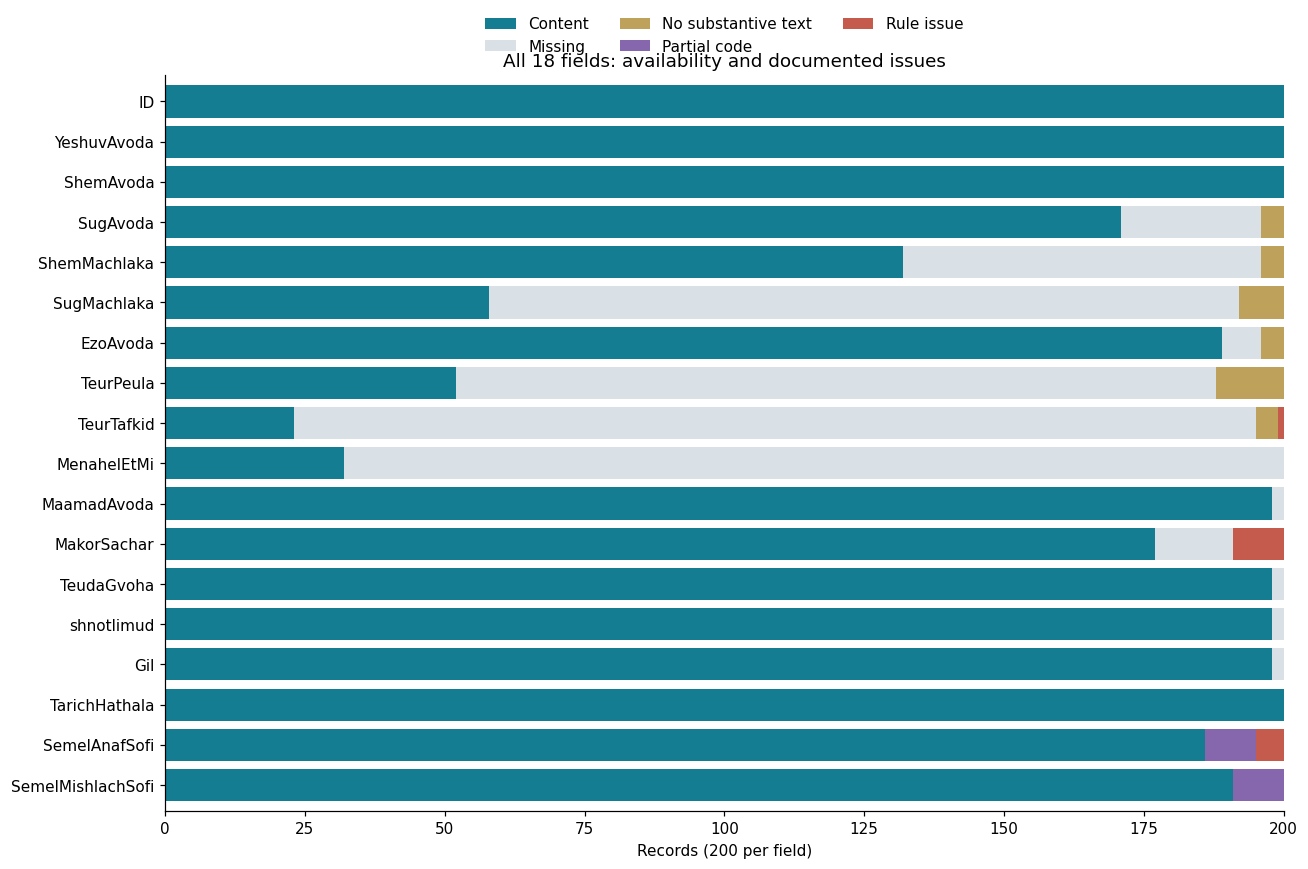

In [5]:
cell_states = pd.DataFrame('Content', index=survey_records.index, columns=survey_records.columns)
cell_states[survey_records.isna()] = 'Missing'
for field in TEXT_FIELDS:
    special = text_states[field].isin(['__reference__', '__withheld__', '__invalid__'])
    cell_states.loc[special, field] = 'No substantive text'
for field in ['SemelAnafSofi', TARGET_FIELD]:
    cell_states.loc[survey_records[field].str.contains('X', na=False), field] = 'Partial code'
for issue in source_issues.itertuples():
    cell_states.loc[survey_records.ID.eq(issue.ID), issue.field] = 'Rule issue'
state_order = ['Content', 'Missing', 'No substantive text', 'Partial code', 'Rule issue']
data_quality_counts = cell_states.apply(pd.Series.value_counts).T.reindex(columns=state_order, fill_value=0).fillna(0).astype(int)
figure, axis = plt.subplots(figsize=(12, 8))
data_quality_counts.iloc[::-1].plot.barh(stacked=True, ax=axis, width=0.8,
    color=['#147d92', '#d9e0e6', '#bea15a', '#8666ac', '#c45b4d'])
axis.set(xlabel='Records (200 per field)', ylabel='', xlim=(0, 200), title='All 18 fields: availability and documented issues')
axis.legend(loc='lower center', bbox_to_anchor=(0.5, 1.01), ncol=3, frameon=False)
figure.tight_layout()
figure.savefig(OUTPUT_DIRECTORY / 'all_fields_quality.png', dpi=160)
plt.show()

## 6. הכנה עקבית שומרת על משמעות גם בקלט חסר
כדי שהאימון והחיזוי יקבלו אותם מצבים, משתמשים בפונקציית הכנה אחת. היא מנרמלת Unicode ורווחים, מסמנת את מצבי אי-המסירה, ומיישמת את תנאי מקור השכר. קוד קטגוריאלי לא מוכר מקבל מצב לא תקין. כמות לא ניתנת לפענוח נשארת חסרה. הטבלה המקורית והדוח נשארים זמינים, ולכן ההמרה אינה מסתירה את הבעיה.

השלמת חציון, אוצר המילים, משקלי IDF, קידוד קטגוריות וקנה המידה יילמדו בהמשך בתוך כל קפל אימון. השלב הנוכחי פועל על כל שורה בנפרד, בלי לחשב ממוצע או ללמוד משורות אחרות. התוצאה היא קלט אחיד, עם כל שדה במקומו המקורי.

In [6]:
def prepare_model_inputs(records):
    prepared_inputs = pd.DataFrame(index=records.index)
    for field in TEXT_FIELDS:
        prepared_inputs[field] = normalize_text(records[field]).replace(TEXT_STATES).astype(str)
    for field in CATEGORY_FIELDS:
        if allowed_codes[field]:
            numbers = pd.to_numeric(records[field], errors='coerce')
            valid_numbers = numbers.where(numbers.isin(allowed_codes[field]))
            categories = valid_numbers.astype('Int64').astype('string').fillna('__missing__')
            invalid_values = records[field].notna() & valid_numbers.isna()
            categories = categories.mask(invalid_values, '__invalid__')
        else:
            categories = normalize_text(records[field]).replace(TEXT_STATES)
        prepared_inputs[field] = categories.astype(str)
    employment_status = pd.to_numeric(records.MaamadAvoda, errors='coerce')
    known_status = employment_status.isin(allowed_codes['MaamadAvoda'])
    prepared_inputs.loc[known_status & ~employment_status.isin([1, 5]), 'MakorSachar'] = '__not_applicable__'
    prepared_inputs.loc[~known_status, 'MakorSachar'] = '__applicability_unknown__'
    for field in ['Gil', 'shnotlimud']:
        numbers = pd.to_numeric(records[field], errors='coerce')
        prepared_inputs[field] = numbers.where(numbers.ge(0) & numbers.mod(1).eq(0)).astype(float)
    prepared_inputs['start_year'] = pd.to_datetime(records.TarichHathala, errors='coerce').dt.year.astype(float)
    return prepared_inputs

model_inputs = prepare_model_inputs(survey_records)
assert set(model_inputs) == set(TEXT_FIELDS + CATEGORY_FIELDS + NUMBER_FIELDS)
display(model_inputs.head())

,SugAvoda,ShemMachlaka,SugMachlaka,EzoAvoda,TeurPeula,TeurTafkid,YeshuvAvoda,ShemAvoda,MenahelEtMi,MaamadAvoda,MakorSachar,TeudaGvoha,Gil,shnotlimud,start_year
0,"איסוף, עיבוד ופרסום נתונים",מיקרו כלכלה,טיפול בנתוני מיקרו,סגן מנהל אגף,__reference__,סגן מנהל אגף,ירושלים,"למ""ס",3,1,1,6,55.0,22.0,2020.0
1,טיפול בחולים,רדיואתרפיה,טיפול בחולי סרטן,טכנאית רדיותרפיה,__reference__,__reference__,ירושלים,בית חולים הדסה עין כרם,__missing__,1,1,6,55.0,22.0,2022.0
2,מתן שירות למשתמשים באתר gov,תמיכה בלקוחות,__reference__,נותנת תמיכה ללקוחות שמבקשים עזרה,מסבירה איך להשתמש בשירותים ממשלתיים באתר האינטרנט,__missing__,באר שבע,קריית הממשלה,__missing__,1,1,5,29.0,15.0,2021.0
3,בית ספר יסודי,שמירה,__missing__,שומר בבית הספר,__missing__,__missing__,תל אביב,משרד החינוך,__missing__,1,2,3,48.0,12.0,2024.0
4,מטפל בקשיש במשפחה,__missing__,__missing__,מטפל בקשיש,"נותן אוכל, עוזר בניקיון בית, עוזר להתרחץ",__missing__,תל אביב,אמיר כהן,__missing__,1,1,4,42.0,14.0,2010.0


## 7. חזרות וקודים נדירים קובעים מה באמת ניתן לבדוק
כדי למנוע מתיאורים זהים להופיע משני צדי החלוקה, בונים קבוצות לפי ששת תיאורי הפעילות, ללא מעסיק, יישוב או יעד. זהו מבחן הכללה לתיאורים שלא נראו, ולא זיהוי של נסקרים. שורות שאין בהן שום תיאור ענייני מקבלות קבוצות נפרדות, כדי שלא נניח זהות רק משום שהן ריקות.

לא מוחקים חזרות ולא משלימים משורה אחרת: גם שני אנשים שונים יכולים לתת אותן תשובות. סתירות בין תוויות מדווחות בלי "לתקן" את המיעוט. למשל, בקבוצת תיאורי המעבדה בבית החולים מופיעים `3311` ו-`3211`. הקובץ אינו מוכיח איזו תווית נכונה. לעומת זאת, `335X` ו-`3354` תואמים בספרות הידועות ואינם נספרים כסתירה בין קודים מלאים.

הטבלאות והתרשים המשותף יראו כמה תיאורים חוזרים וכמה מחלקות נתמכות בדוגמה או בקבוצה אחת בלבד. מחלקה שיש לה קבוצה אחת אינה יכולה להיות מיוצגת גם באימון וגם בוולידציה מופרדת קבוצות. זו מגבלת מדידה, ולא סיבה למחוק אותה מהדיווח.

Repeated source rows beyond the first, excluding ID: 11
Description groups: 121 | Conflicting groups: 1


,ID,SugAvoda,ShemMachlaka,SugMachlaka,EzoAvoda,TeurPeula,TeurTafkid,SemelMishlachSofi
1,2,טיפול בחולים,רדיואתרפיה,טיפול בחולי סרטן,טכנאית רדיותרפיה,"כנ""ל","כנ""ל",3311
32,33,טיפול בחולים,רדיואתרפיה,טיפול בחולי סרטן,טכנאית רדיותרפיה,"כנ""ל","כנ""ל",3211
64,65,טיפול בחולים,רדיואתרפיה,טיפול בחולי סרטן,טכנאית רדיותרפיה,"כנ""ל","כנ""ל",3211
95,96,טיפול בחולים,רדיואתרפיה,טיפול בחולי סרטן,טכנאית רדיותרפיה,"כנ""ל","כנ""ל",3211


,records,groups
code,,
1212,1,1
1221,1,1
1330,1,1
1345,1,1
2113,1,1
2423,1,1
2411,1,1
2330,1,1
2431,1,1


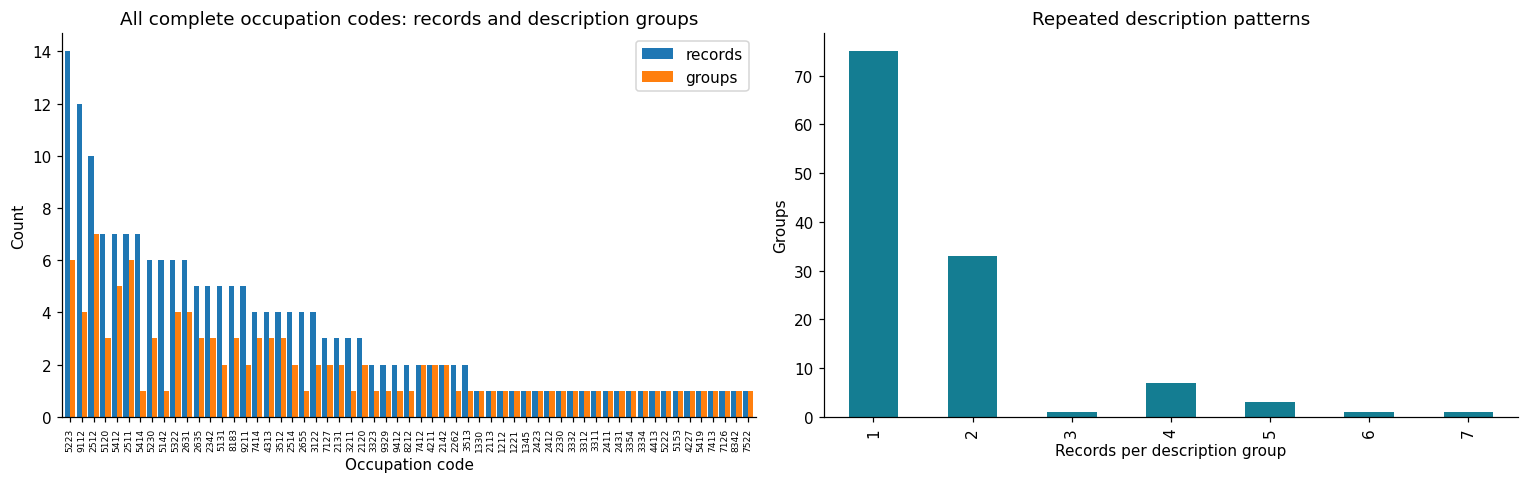

In [7]:
description_groups = pd.Series(pd.MultiIndex.from_frame(model_inputs[DESCRIPTION_FIELDS]).factorize()[0],
                               index=survey_records.index).astype(str)
has_description = ~model_inputs[DESCRIPTION_FIELDS].apply(lambda column: column.str.startswith('__')).all(axis=1)
description_groups.loc[~has_description] = 'empty_record_' + survey_records.loc[~has_description, 'ID'].astype(str)
group_summary = survey_records.assign(description_group=description_groups).groupby('description_group').agg(
    records=('ID', 'size'))
complete_code_counts = survey_records.loc[complete_labels].assign(
    description_group=description_groups.loc[complete_labels]).groupby('description_group')[TARGET_FIELD].nunique()
group_summary['distinct_complete_codes'] = complete_code_counts.reindex(group_summary.index, fill_value=0)
conflicting_groups = group_summary.index[group_summary.distinct_complete_codes.gt(1)]
display(survey_records.loc[description_groups.isin(conflicting_groups), ['ID', *DESCRIPTION_FIELDS, TARGET_FIELD]])
print('Repeated source rows beyond the first, excluding ID:', survey_records.drop(columns='ID').duplicated().sum())
print('Description groups:', description_groups.nunique(), '| Conflicting groups:', len(conflicting_groups))

labeled_inputs = model_inputs.loc[complete_labels].reset_index(drop=True)
occupation_codes = survey_records.loc[complete_labels, TARGET_FIELD].astype(str).reset_index(drop=True)
labeled_groups = description_groups.loc[complete_labels].reset_index(drop=True)
labeled_record_ids = survey_records.loc[complete_labels, 'ID'].reset_index(drop=True)
class_support = pd.DataFrame({'code': occupation_codes, 'description_group': labeled_groups}).groupby('code').agg(
    records=('description_group', 'size'), groups=('description_group', 'nunique'))
display(class_support.sort_values('records'))
figure, axes = plt.subplots(1, 2, figsize=(14, 4.5))
class_support.sort_values('records', ascending=False)[['records', 'groups']].plot.bar(ax=axes[0], width=0.9)
axes[0].set(title='All complete occupation codes: records and description groups', xlabel='Occupation code', ylabel='Count')
axes[0].tick_params(axis='x', labelsize=6)
group_summary.records.value_counts().sort_index().plot.bar(ax=axes[1], color='#147d92')
axes[1].set(title='Repeated description patterns', xlabel='Records per description group', ylabel='Groups')
figure.tight_layout()
figure.savefig(OUTPUT_DIRECTORY / 'labels_and_repetition.png', dpi=160)
plt.show()

## 8. חלוקה הוגנת לפני למידת ייצוג או בחירת מודל
כדי שההשוואה תבחן הכללה ולא זיכרון של אותו תיאור, שומרים קבוצת בדיקה ומפרידים את קבוצות התיאור גם בעשרת קפלי האימון. `GroupKFold` מתאים לאילוץ הזה, אך אינו מבטיח שכל מקצוע יופיע בכל צד. הטבלה תציג את גודל הקפלים ואת מספר הרשומות שמחלקתן חסרה באימון.

הבחירה תתבסס על macro-F1 ממוצע בקפלי האימון, לצד accuracy ועלות הריצה. משתמשים בהגדרת scikit-learn הרגילה: ממוצע F1 על איחוד המחלקות האמיתיות והחזויות בכל קפל, עם אפס למקרה לא מוגדר. לכן השוואות נעשות על אותם קפלים, וסטיית התקן ביניהם מתארת שונות, לא רווח סמך.

לא מכוונים חלוקה לפי תוצאה ולא מסירים מחלקות נדירות. ציון הבחירה לאחר חיפוש אינו אומדן נטול הטיה. קבוצת הבדיקה נשמרת מהכוונון בהרצה זו. הקובץ אינו מדגם חיצוני שלא נחשף במהלך פיתוח הפתרון, ולכן זו הדגמת תהליך ולא בדיקת ייצור עצמאית.

כדי למדוד איכות במקום שבו קיימת תשובה להשוואה, מפרידים בין **בדיקה עם תווית** לבין **חיזוי ללא תווית מלאה**:

| קבוצה | מספר רשומות | מה עושים בה |
|---|---:|---|
| אימון עם קוד מלא | 156 | התאמת העיבוד והמודלים מחדש בכל קפל, והשוואת מפרטים ב-CV |
| בדיקה עם קוד מלא | 35 | חיזוי לאחר בחירה ב-CV וחישוב התאמה לקוד הידני שהוחזק בצד |
| קוד יעד המכיל X | 9 | הצעת קוד לאחר אימון המפרט הנבחר על כל 191 התוויות המלאות |

רשומות X אינן סט בדיקה למדדי accuracy או F1: אין עבורן קוד מלא ידוע להשוואה. התאמה לספרות הידועות ב-1XXX אינה מוכיחה שהקוד המלא שחזינו נכון. במימוש הפשוט למטלה זו הן אינן משתתפות גם בהתאמת העיבוד או בכוונון. שימוש בלמידה עם תוויות חלקיות אפשרי במסגרת נפרדת, אך דורש הנחות נוספות שאינן נדרשות כאן. אין צורך בשיטה כזו כדי לעמוד במשימה.

כדי למדוד גם הצלחה כוללת וגם ביצועים במקצועות פחות שכיחים, מציגים accuracy לצד macro-F1. בסיווג חד-תוויתי רב-מחלקתי על כלל המחלקות, micro-recall שווה בדיוק ל-accuracy, ולכן אין אלה שתי ראיות עצמאיות. דוח המחלקות מציג גם recall לכל קוד וממוצע macro. הבחירה במטריקה והחלוקה התקינה חשובות להערכת המטלה, גם כאשר גובה הציון הסינתטי אינו יעד ההגשה.


In [8]:
training_positions, test_positions = next(GroupShuffleSplit(n_splits=1, test_size=0.22,
    random_state=RANDOM_SEED).split(labeled_inputs, occupation_codes, labeled_groups))
training_features, test_features = labeled_inputs.iloc[training_positions], labeled_inputs.iloc[test_positions]
training_codes, test_codes = occupation_codes.iloc[training_positions], occupation_codes.iloc[test_positions]
training_groups = labeled_groups.iloc[training_positions]
validation_splits = list(GroupKFold(n_splits=10, shuffle=True, random_state=RANDOM_SEED).split(
    training_features, training_codes, training_groups))
assert set(training_groups).isdisjoint(labeled_groups.iloc[test_positions])
fold_records = []
for fold_number, (fit_positions, validation_positions) in enumerate(validation_splits, 1):
    assert set(training_groups.iloc[fit_positions]).isdisjoint(training_groups.iloc[validation_positions])
    fold_records.append({'fold': fold_number, 'training_records': len(fit_positions),
        'validation_records': len(validation_positions), 'unseen_label_records': int(
            (~training_codes.iloc[validation_positions].isin(training_codes.iloc[fit_positions])).sum())})
fold_overview = pd.DataFrame(fold_records)
assert sorted(np.concatenate([positions for _, positions in validation_splits])) == list(range(len(training_features)))
display(fold_overview)
print('Training / test records:', len(training_features), len(test_features))
print('Test records with unseen labels:', (~test_codes.isin(training_codes)).sum())

Training / test records: 156 35
Test records with unseen labels: 7


,fold,training_records,validation_records,unseen_label_records
0,1,138,18,6
1,2,147,9,5
2,3,140,16,9
3,4,140,16,0
4,5,134,22,2
5,6,135,21,13
6,7,141,15,7
7,8,142,14,4
8,9,143,13,6
9,10,144,12,7


## 9. בחירת ייצוג נובעת ממשמעות השדה
כדי שלא נבלבל בין טיפוס אחסון ובין אופן המענה, מפרידים בין מה שמתועד ובין החלטת מידול. ארבע רשימות ערכים ממוספרות מוגדרות במפורש ב-Metadata: ניהול, מעמד עבודה, מקור שכר ותעודה. אלה קטגוריות גם כשהן נשמרות כמספר. בשדות הטקסט אין רשימת ערכים מותרת ואין תיאור של ממשק המענה. לכן אי אפשר לקבוע מהקובץ אם היו תיבות טקסט או רשימות בחירה.

| שדות | המשמעות המתועדת וההחלטה | מה נבדק במקום להניח |
|---|---|---|
| `YeshuvAvoda`, `ShemAvoda` | ישויות: יישוב ומקום עבודה. One-hot כקו בסיס, עם טיפול בישות שלא נראתה | שם מקום העבודה כולל לעיתים תיאור כללי. הפשרה ב-One-hot היא אובדן דמיון לשם חדש |
| `SugAvoda`, `SugMachlaka`, `EzoAvoda`, `TeurPeula` | פעילות ועשייה: תיאורים לשוניים, ולכן TF-IDF | איכות הייצוג ואובדן מידע באשכולות נבדקים על אותם קפלים |
| `ShemMachlaka`, `TeurTafkid` | שם מחלקה ותואר משרה: אין מילון סגור מתועד. ניסוחים חדשים יכולים לשאת משמעות | 16 ערכים נצפים בתואר המשרה אינם מילון סגור. נדרשת הגדרת השאלון כדי לאשר זאת |
| ארבעת הקודים הממוספרים | תחומים סגורים מתועדים: One-hot | ערכים מחוץ לתחום מסומנים במפורש |
| גיל, שנות לימוד ושנת תחילת תפקיד | כמויות ולא תוויות | נשמרות מספריות. לא נגזר ותק ללא תאריך הסקר |

חזרתיות או מספר קטן של ערכים שנצפו אינם הוכחה לשאלון סגור. מנגד, שם יישוב אינו דורש TF-IDF רק משום שהוא TEXT. ההחלטה נובעת מהמשמעות. אימות סוג ממשק המענה נותר שאלה להטמעה, ולא עובדה שממציאים מהמדגם.

## 10. שני מסלולים מפורשים לפני בחירת מסווג
כדי לבדוק אם grouping מוסיף מידע שימושי או מאבד הבחנות חשובות, בונים שני ייצוגים של אותם שדות:

1. **Direct TF-IDF:** ששת התיאורים מיוצגים במשקלי TF-IDF. שדות הקטגוריה ב-One-hot. מוצגים המשקלים הגולמיים ללא L2. בהשוואת המודלים נבחן גם L2 כהגדרה בתוך מסלול זה.
2. **Cluster one-hot:** בכל שדה תיאור מבצעים TF-IDF ללא smoothing, נרמול L2, בחירת מספר קבוצות עם K-means, וקידוד One-hot של זהות הקבוצה. גם שדות הקטגוריה מקודדים ב-One-hot.

בשני המסלולים `smooth_idf=False` ו-TF רגיל. מימוש scikit-learn משתמש ב-`idf = log(n / df) + 1` גם בלי smoothing. לא מחליפים זאת בנוסחה אחרת. L2 מביא כל וקטור לא-אפס לאורך יחידה, כך שמכפלה פנימית בין שני וקטורים מנורמלים שווה לדמיון קוסינוס. הוא מפחית השפעה של אורך התיאור. האורך עשוי לשאת מידע, ולכן במסלול הישיר הוא נבדק ולא מוכרע מראש. לפני K-means הנרמול תמיד מופעל. נרמול אורך הווקטור אינו איזון של שכיחויות המקצועות.

לכל שדה נבחנים כל מספרי הקבוצות השלמים מ-2 עד מספר הווקטורים השונים פחות 1. בוחרים את ציון Calinski-Harabasz הגבוה ביותר, ובשוויון את המספר הקטן יותר. זה מדד לפיזור בין ובתוך קבוצות, לא לאיכות סיווג מקצועי. כל ניסוח ענייני שונה מקבל משקל אחד בבחירת הקבוצות, כדי שחזרות סינתטיות לא יכריעו את הגאומטריה. IDF עצמו נלמד משורות האימון.

מצבי חסר, אי-מסירה והפניה נשארים קטגוריות מפורשות ואינם משתתפים בבחירת קבוצות התוכן. כשאין די וקטורים שונים, נשמרים מצב ריק או עד שני מרכזים ללא אופטימיזציית CH. טקסט ללא מונח מוכר מקבל קטגוריית טקסט חדש, ולא קבוצה סמנטית מומצאת. מצב שלא הופיע באימון יקודד בווקטור אפסים על ידי OneHotEncoder עם handle_unknown="ignore". המתאם הקצר הבא מחבר את המימושים הקיימים של TF-IDF, KMeans ו-OneHotEncoder. הוא אינו מממש מחדש את האלגוריתמים.

### מדוע שתי הדרכים ראויות להשוואה
כדי לבחור ייצוג לפי תכונות הנתונים, בוחנים מה כל דרך משמרת ומה היא עשויה לאבד. שתי הדרכים הן השערות מידול תקפות. ההערכה בודקת איזו מהן מועילה בתנאים שנמדדו.

| שיקול | TF-IDF ישיר | קבוצות ואז One-hot |
|---|---|---|
| ראיה שהמסווג מקבל | משקל של כל מונח, לרבות מונח נדיר שמבדיל בין מקצועות | זהות קבוצה לכל שדה, שיכולה לאחד ניסוחים קרובים במרחב הטקסט |
| מתי יש סיבה לצפות לתועלת | מילים מסוימות וצירופים של ראיות משדות שונים חשובים לסיווג | יש ניסוחים רבים וחזרתיים עם קרבה שימושית, ומספר קבוצות סביר מרכז אותם |
| מגבלה אפשרית | שגיאות כתיב ומונחים חדשים מפצלים את הראיות, ואוצר מילים רחב דורש רגולריזציה | קבוצה עלולה לאחד מקצועות שצריך להפריד. K גבוה עלול להשאיר כמעט קבוצה לכל ניסוח |
| מחיר חישובי | יצירת TF-IDF ואימון המסווג על המונחים | אותה יצירת TF-IDF, בתוספת למידת מרכזים, שיוך לקבוצה ואימון המסווג |
| מה מלמדת הבדיקה | האם שמירת פירוט המילים מועילה להכללה | האם המרת הפירוט לקטגוריות מועילה מספיק כדי להצדיק את אובדן המידע והעלות |

קבוצות TF-IDF מבטאות קרבה בייצוג הלשוני שנבחר. הן אינן הוכחה לשקילות סמנטית או לאותו משלח יד. גם בקבוצות קטנות מאוד מתקבל מיפוי לתיאור מייצג, אך לא בהכרח איגוד רחב של ניסוחים. לכן נדרשת גם הערכת הסיווג, ולא רק מקסום CH.


In [9]:
from sklearn.base import BaseEstimator, TransformerMixin

def text_vectorizer(normalization=None):
    return TfidfVectorizer(smooth_idf=False, norm=normalization, sublinear_tf=False,
                          token_pattern=r'(?u)\b\w+\b')

class TextGroups(BaseEstimator, TransformerMixin):
    def __init__(self, random_state=42):
        self.random_state = random_state

    def fit(self, texts, labels=None):
        texts = pd.Series(np.asarray(texts), dtype=str)
        self.vectorizer_ = text_vectorizer('l2').fit(texts)
        content = texts.loc[~texts.str.startswith('__')].drop_duplicates()
        self.scores_, self.model_, self.selected_clusters_ = [], None, 0
        if content.empty:
            return self
        vectors = self.vectorizer_.transform(content)
        distinct_vectors = np.unique(vectors.toarray(), axis=0)
        distinct_vectors = distinct_vectors[np.linalg.norm(distinct_vectors, axis=1) > 0]
        assert np.allclose(np.linalg.norm(distinct_vectors, axis=1), 1)
        self.scores_, self.model_ = [], None
        if len(distinct_vectors) == 0:
            return self
        best_score = -np.inf
        cluster_counts = range(2, len(distinct_vectors)) if len(distinct_vectors) > 2 else [len(distinct_vectors)]
        for cluster_count in cluster_counts:
            candidate = KMeans(n_clusters=cluster_count, n_init=10, max_iter=300,
                               random_state=self.random_state).fit(distinct_vectors)
            score = calinski_harabasz_score(distinct_vectors, candidate.labels_) if len(distinct_vectors) > 2 else np.nan
            self.scores_.append({'clusters': cluster_count, 'CH': score, 'iterations': candidate.n_iter_})
            if self.model_ is None or score > best_score:
                self.model_, best_score = candidate, score
        self.selected_clusters_ = self.model_.n_clusters
        return self

    def transform(self, texts):
        texts = pd.Series(np.asarray(texts), dtype=str)
        categories = texts.where(texts.str.startswith('__'), '__unseen_text__').to_numpy(dtype=object)
        if self.model_ is not None:
            vectors = self.vectorizer_.transform(texts)
            usable = ~texts.str.startswith('__').to_numpy() & (vectors.getnnz(axis=1) > 0)
            if usable.any():
                categories[usable] = [f'group_{number}' for number in self.model_.predict(vectors[usable].toarray())]
        return categories.reshape(-1, 1)

def build_preprocessor(path='Direct TF-IDF', normalization=None):
    text_transformers = []
    for field in TEXT_FIELDS:
        encoder = text_vectorizer(normalization) if path == 'Direct TF-IDF' else Pipeline([
            ('groups', TextGroups(RANDOM_SEED)), ('onehot', OneHotEncoder(handle_unknown='ignore'))])
        text_transformers.append((field, encoder, field))
    return ColumnTransformer(text_transformers + [
        ('categories', OneHotEncoder(handle_unknown='ignore'), CATEGORY_FIELDS),
        ('numbers', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
                              ('scale', MinMaxScaler(clip=True))]), NUMBER_FIELDS)
    ], remainder='drop', sparse_threshold=0)

### טבלאות המאפיינים מציגות מה המסווג יקבל בפועל
כדי לבדוק את הייצוג לפני המודלים, מתאימים כעת את שני המסלולים לחלק האימון בלבד ומציגים דוגמאות מספריות, ממדים ומספר קבוצות לכל שדה. אלה עותקי המחשה. בוולידציה תתבצע התאמה חדשה בתוך כל קפל.

במסלול הישיר רואים משקלי TF-IDF אמיתיים של מונחים, ללא L2. במסלול הקבוצות רואים ערכי 0/1. גם שם גיל, שנות לימוד ושנת התחלה נשארים כמותיים. "כל הטקסט ב-One-hot" אינו הופך כמויות לקטגוריות. הטבלאות המלאות נשמרות, והתרשים המאוחד מציג את בחירת מספר הקבוצות בכל השדות יחד.

Complete training matrices: (156, 572) (156, 359)


,field,raw_tfidf_dimensions,content_clusters,onehot_dimensions
0,SugAvoda,101,62,63
1,ShemMachlaka,66,47,48
2,SugMachlaka,49,25,27
3,EzoAvoda,137,67,68
4,TeurPeula,74,22,24
5,TeurTafkid,30,11,14


,SugAvoda / פיתוח,SugAvoda / תוכנה,SugAvoda / בית,ShemMachlaka / עובד,ShemMachlaka / שמירה,ShemMachlaka / משק,SugMachlaka / טיפול,SugMachlaka / בחולי,SugMachlaka / לעובדים,EzoAvoda / הספר,EzoAvoda / בית,EzoAvoda / של,TeurPeula / של,TeurPeula / עוזר,TeurPeula / נותן,TeurTafkid / כלכלן,TeurTafkid / טכנאי,TeurTafkid / מחשבים
0,0.000,0.000,0.000,0.0,0.000,0.0,3.747,4.664,0.0,0.000,0.0,0.00,0.0,0.000,0.00,0.00,0.000,0.000
1,0.000,0.000,3.853,0.0,4.104,0.0,0.000,0.000,0.0,3.853,0.0,0.00,0.0,0.000,0.00,0.00,0.000,0.000
2,0.000,0.000,0.000,0.0,0.000,0.0,0.000,0.000,0.0,0.000,0.0,0.00,0.0,8.516,4.44,0.00,0.000,0.000
3,0.000,0.000,0.000,0.0,0.000,0.0,0.000,0.000,0.0,0.000,0.0,0.00,0.0,0.000,0.00,0.00,0.000,0.000
4,0.000,0.000,0.000,0.0,0.000,0.0,0.000,0.000,0.0,0.000,0.0,0.00,0.0,0.000,0.00,0.00,0.000,0.000
5,3.565,3.652,0.000,0.0,0.000,0.0,0.000,0.000,0.0,0.000,0.0,0.00,0.0,0.000,0.00,0.00,0.000,0.000
6,0.000,0.000,0.000,0.0,0.000,0.0,0.000,0.000,0.0,0.000,0.0,0.00,0.0,0.000,4.44,0.00,4.951,4.951
7,0.000,0.000,0.000,0.0,0.000,0.0,3.747,0.000,0.0,0.000,0.0,3.97,0.0,0.000,0.00,4.44,0.000,0.000


,SugAvoda / __missing__,SugAvoda / group_0,SugAvoda / group_1,SugAvoda / group_10,SugAvoda / group_11,SugAvoda / group_12,SugAvoda / group_13,SugAvoda / group_14,SugAvoda / group_15,SugAvoda / group_16,SugAvoda / group_17,SugAvoda / group_18,SugAvoda / group_19,SugAvoda / group_2,SugAvoda / group_20,SugAvoda / group_21,SugAvoda / group_22,SugAvoda / group_23,SugAvoda / group_24,SugAvoda / group_25,SugAvoda / group_26,SugAvoda / group_27,SugAvoda / group_28,SugAvoda / group_29,SugAvoda / group_3,SugAvoda / group_30,SugAvoda / group_31,SugAvoda / group_32,SugAvoda / group_33,SugAvoda / group_34,SugAvoda / group_35,SugAvoda / group_36,SugAvoda / group_37,SugAvoda / group_38,SugAvoda / group_39,SugAvoda / group_4,SugAvoda / group_40,SugAvoda / group_41,SugAvoda / group_42,SugAvoda / group_43,SugAvoda / group_44,SugAvoda / group_45,SugAvoda / group_46,SugAvoda / group_47,SugAvoda / group_48,SugAvoda / group_49,SugAvoda / group_5,SugAvoda / group_50,SugAvoda / group_51,SugAvoda / group_52,SugAvoda / group_53,SugAvoda / group_54,SugAvoda / group_55,SugAvoda / group_56,SugAvoda / group_57,SugAvoda / group_58,SugAvoda / group_59,SugAvoda / group_6,SugAvoda / group_60,SugAvoda / group_61,SugAvoda / group_7,SugAvoda / group_8,SugAvoda / group_9,ShemMachlaka / __missing__,ShemMachlaka / group_0,ShemMachlaka / group_1,ShemMachlaka / group_10,ShemMachlaka / group_11,ShemMachlaka / group_12,ShemMachlaka / group_13,ShemMachlaka / group_14,ShemMachlaka / group_15,ShemMachlaka / group_16,ShemMachlaka / group_17,ShemMachlaka / group_18,ShemMachlaka / group_19,ShemMachlaka / group_2,ShemMachlaka / group_20,ShemMachlaka / group_21,ShemMachlaka / group_22,ShemMachlaka / group_23,ShemMachlaka / group_24,ShemMachlaka / group_25,ShemMachlaka / group_26,ShemMachlaka / group_27,ShemMachlaka / group_28,ShemMachlaka / group_29,ShemMachlaka / group_3,ShemMachlaka / group_30,ShemMachlaka / group_31,ShemMachlaka / group_32,ShemMachlaka / group_33,ShemMachlaka / group_34,ShemMachlaka / group_35,ShemMachlaka / group_36,ShemMachlaka / group_37,ShemMachlaka / group_38,ShemMachlaka / group_39,ShemMachlaka / group_4,ShemMachlaka / group_40,ShemMachlaka / group_41,ShemMachlaka / group_42,ShemMachlaka / group_43,ShemMachlaka / group_44,ShemMachlaka / group_45,ShemMachlaka / group_46,ShemMachlaka / group_5,ShemMachlaka / group_6,ShemMachlaka / group_7,ShemMachlaka / group_8,ShemMachlaka / group_9,SugMachlaka / __missing__,SugMachlaka / __reference__,SugMachlaka / group_0,SugMachlaka / group_1,SugMachlaka / group_10,SugMachlaka / group_11,SugMachlaka / group_12,SugMachlaka / group_13,SugMachlaka / group_14,SugMachlaka / group_15,SugMachlaka / group_16,SugMachlaka / group_17,SugMachlaka / group_18,SugMachlaka / group_19,SugMachlaka / group_2,SugMachlaka / group_20,SugMachlaka / group_21,SugMachlaka / group_22,SugMachlaka / group_23,SugMachlaka / group_24,SugMachlaka / group_3,SugMachlaka / group_4,SugMachlaka / group_5,SugMachlaka / group_6,SugMachlaka / group_7,SugMachlaka / group_8,SugMachlaka / group_9,EzoAvoda / __missing__,EzoAvoda / group_0,EzoAvoda / group_1,EzoAvoda / group_10,EzoAvoda / group_11,EzoAvoda / group_12,EzoAvoda / group_13,EzoAvoda / group_14,EzoAvoda / group_15,EzoAvoda / group_16,EzoAvoda / group_17,EzoAvoda / group_18,EzoAvoda / group_19,EzoAvoda / group_2,EzoAvoda / group_20,EzoAvoda / group_21,EzoAvoda / group_22,EzoAvoda / group_23,EzoAvoda / group_24,EzoAvoda / group_25,EzoAvoda / group_26,EzoAvoda / group_27,EzoAvoda / group_28,EzoAvoda / group_29,EzoAvoda / group_3,EzoAvoda / group_30,EzoAvoda / group_31,EzoAvoda / group_32,EzoAvoda / group_33,EzoAvoda / group_34,EzoAvoda / group_35,EzoAvoda / group_36,EzoAvoda / group_37,EzoAvoda / group_38,EzoAvoda / group_39,EzoAvoda / group_4,EzoAvoda / group_40,EzoAvoda / group_41,EzoAvoda / group_42,EzoAvoda / group_43,EzoAvoda / group_44,EzoAvoda / group_45,EzoAvoda / group_46,EzoAvoda / group_47,EzoAvoda / group_48,EzoAvoda / group_49,EzoAvoda / group_5,EzoAvoda / group_50,EzoAvoda / group_51,EzoAv

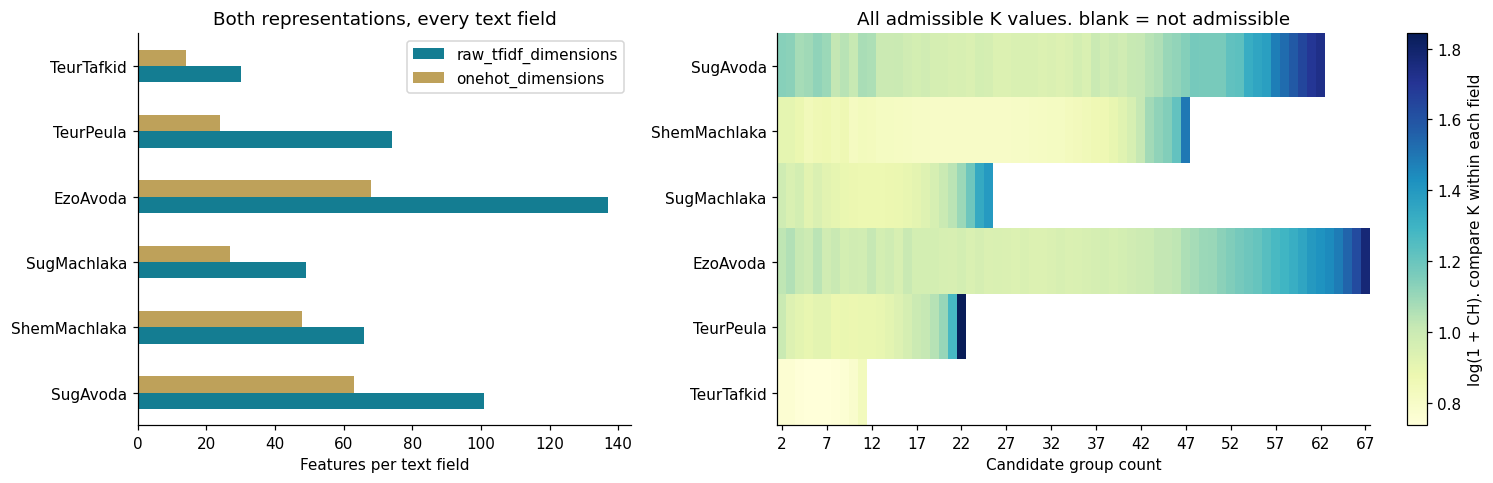

In [10]:
direct_preview = build_preprocessor().fit(training_features, training_codes)
cluster_preview = build_preprocessor('Cluster one-hot').fit(training_features, training_codes)
direct_matrix = direct_preview.transform(training_features)
cluster_matrix = cluster_preview.transform(training_features)
raw_tfidf_examples, cluster_examples, cluster_search_records, cluster_memberships = [], [], [], []
representation_records = []
for field in TEXT_FIELDS:
    vectorizer = direct_preview.named_transformers_[field]
    weights = vectorizer.transform(training_features[field]).toarray()
    terms = vectorizer.get_feature_names_out()
    substantive_terms = np.flatnonzero(~pd.Series(terms).str.startswith('__'))
    chosen_terms = substantive_terms[np.argsort(-weights[:, substantive_terms].sum(axis=0))[:3]]
    raw_tfidf_examples.append(pd.DataFrame(weights[:, chosen_terms], columns=[field + ' / ' + terms[index] for index in chosen_terms]))
    group_pipeline = cluster_preview.named_transformers_[field]
    learned_groups = group_pipeline.named_steps['groups']
    group_matrix = group_pipeline.transform(training_features[field]).toarray()
    cluster_examples.append(pd.DataFrame(group_matrix, columns=[field + ' / ' + category
        for category in group_pipeline.named_steps['onehot'].categories_[0]]))
    representation_records.append({'field': field, 'raw_tfidf_dimensions': weights.shape[1],
        'content_clusters': getattr(learned_groups, 'selected_clusters_', 0),
        'onehot_dimensions': group_matrix.shape[1]})
    cluster_search_records.extend({'field': field, **result} for result in learned_groups.scores_)
    cluster_memberships.extend({'field': field, 'text': text, 'group': category}
        for text, category in zip(training_features[field], learned_groups.transform(training_features[field]).ravel()))
raw_tfidf_sample = pd.concat(raw_tfidf_examples, axis=1)
onehot_sample = pd.concat(cluster_examples, axis=1)
representation_overview = pd.DataFrame(representation_records)
cluster_search_results = pd.DataFrame(cluster_search_records)
display(representation_overview)
display(raw_tfidf_sample.head(8).round(3))
display(onehot_sample.head(8))
assert set(np.unique(onehot_sample)).issubset({0, 1})
print('Complete training matrices:', direct_matrix.shape, cluster_matrix.shape)
cluster_scores_matrix = cluster_search_results.pivot(index='field', columns='clusters', values='CH').reindex(TEXT_FIELDS)
figure, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [1, 1.5]})
representation_overview.set_index('field')[['raw_tfidf_dimensions', 'onehot_dimensions']].plot.barh(ax=axes[0], color=['#147d92', '#bea15a'])
axes[0].set(xlabel='Features per text field', ylabel='', title='Both representations, every text field')
heatmap = axes[1].imshow(np.log1p(cluster_scores_matrix), aspect='auto', cmap='YlGnBu')
axes[1].set_yticks(range(len(TEXT_FIELDS)), TEXT_FIELDS)
tick_positions = np.arange(0, len(cluster_scores_matrix.columns), 5)
axes[1].set_xticks(tick_positions, cluster_scores_matrix.columns[tick_positions])
axes[1].set(xlabel='Candidate group count', title='All admissible K values. blank = not admissible')
figure.colorbar(heatmap, ax=axes[1], label='log(1 + CH). compare K within each field')
figure.tight_layout()
figure.savefig(OUTPUT_DIRECTORY / 'two_representations.png', dpi=160)
plt.show()

## 11. פרמטרים נבחרים לפי השפעתם הצפויה על המדגם
כדי לזהות איזו הנחת מודל מתאימה לייצוגים, משווים את כל המשפחות באותם עשרה קפלי אימון. ריבוי מקצועות ומעט דוגמאות לכל מקצוע מכוונים את החיפוש לרגולריזציה, גודל עלים ועומק, ולא לרשתות גדולות. כל הערכים נקבעים לפני קריאת תוצאות הבדיקה. אין הגרלה ואין הבטחה מוקדמת שאלו הערכים הטובים בעולם: זו השוואה מוגבלת ומנומקת.

| מודל | פרמטרים וערכים מפורשים | מדוע דווקא אלה |
|---|---|---|
| LogisticRegression | `C=[0.1, 1, 10]` | עשירית, ברירת המחדל ופי עשרה: טווח לוגריתמי לבדיקת רגולריזציה חזקה, בינונית וחלשה במרחב טקסט רחב |
| RandomForestClassifier | `min_samples_leaf=[1, 2, 4]`, `max_features=['sqrt', 0.5, 1.0]` | עלה יחיד שומר אות נדיר אך עלול לזכור רעש. 2 ו-4 דורשים תמיכה נוספת. sqrt משווה ברירת מחדל דלילה לדגימת מחצית המאפיינים או כולם כשאותות רבים נדירים |
| HistGradientBoostingClassifier | `max_leaf_nodes=[3, 7, 31]` | 3 ו-7 עלים מגבילים אינטראקציות מול ברירת המחדל 31. `min_samples_leaf=2` קבוע כי ברירת המחדל 20 גדולה ביחס למדגם ולמקצועות הנדירים |
| SVC עם RBF | `C=[0.1, 1, 10]` | אותו טווח לוגריתמי לענישה על שגיאות. `gamma='scale'` מתאים את קנה המידה לשונות המאפיינים בתוך כל קפל |
| XGBClassifier | `max_depth=[1, 3, 6]`, `min_child_weight=[0, 0.1, 1]` | גדם ושלוש רמות מגבילים מורכבות מול ברירת המחדל שש. ברירת המחדל 1 עלולה לחסום פיצולים במקצועות נדירים כי Hessian רב-מחלקתי קטן. 0 מסיר חסם זה ו-0.1 בודק סף נמוך פי עשרה עם דרישת תמיכה מסוימת. אין פירושו אפס רשומות לעלה |
| LGBMClassifier | `min_child_samples=[2, 5, 20]` | ברירת המחדל 20 מול 2 לשימור אות נדיר ו-5 להגבלת פיצולים עם מעט תמיכה. 20 עלול למנוע פיצולים שימושיים כאן, ונבדק בפועל. שבעה עלים מגבילים מורכבות |
| CatBoostClassifier | `depth=[2, 4, 6]` | 4, 16 ו-64 עלים לכל היותר בעצים הסימטריים: מגבלה חזקה, בינונית ועומק ברירת המחדל. שישה עלולים כבר להיות גדולים מדי למדגם |
| MLPClassifier | `alpha=[0.0001, 0.01, 1]` | ברירת המחדל 0.0001 מול רגולריזציה חזקה פי 100 ופי 10,000, להגבלת רשת בת 16 יחידות כאשר מספר המאפיינים גדול ממספר הרשומות |
| ComplementNB | `alpha=[0.1, 1, 10]` | בסיס טקסט מהיר: עשירית, Laplace=1 ורגולריזציה חזקה יותר. זהו smoothing של אומדן המסווג, נפרד מ-IDF שנותר ללא smoothing |
| הצבעה רכה של חמישה | `logistic__C=[0.1,1,10]`, `forest__min_samples_leaf=[1,2,4]` | מכווננים יחד רגולריזציה של המודל הליניארי ותמיכה בעלה ביער, לפי ציון האנסמבל. משקלי ההצבעה נשארים אחידים. הרכיבים הם LR, RF, XGBoost, SVC ו-MLP |
| הצבעה קשה של חמישה | `logistic__C=[0.1,1,10]`, `forest__min_samples_leaf=[1,2,4]` | אותן תשע קומבינציות עם קולות מחלקה במקום ממוצע הסתברויות. החיפוש והאימון נפרדים מ-soft |

באנסמבל מכווננים שני פרמטרים משותפים בתוך GridSearchCV על האנסמבל השלם. תשע הקומבינציות נבחנות בכל קפל. weights=None נשאר קבוע, כך שלא מוסיפים כוונון של משקלים למדגם קטן. לא משתמשים בזוכים שנבחרו על כל קפלי האימון כאילו היו בחירות בלתי תלויות בתוך אותם קפלים. לכל מודל לכל היותר שני פרמטרי מסווג בחיפוש, ולכל פרמטר שלושה ערכים בדיוק, ובהם ברירת המחדל המתועדת ושתי חלופות. נרמול None/L2 הוא הגדרת עיבוד נוספת במסלול הישיר. ארבעת מסווגי boosting משתמשים בתקציב קבוע של 40 סבבים ובקצב 0.1, כדי להגביל זמן ריצה של הרשת המלאה. זהו ניסוי להשוואת תהליכים בתקציב מוגבל, ולא מיצוי דיוק של כל ספרייה. אין early stopping על קבוצת הבדיקה. GridSearchCV מקבל את הרשתות עצמן ומחשב את המכפלה הקרטזית המלאה. ParameterGrid משמש רק לשמות ולתיעוד הצירופים באותו סדר.

XGBoost דורש מספרי מחלקות רציפים בכל אימון. `VotingClassifier` עם רכיב יחיד משתמש במקודד התוויות המובנה כדי למפות קודים בתוך הקפל ולהחזיר אותם בחיזוי. זהו מתאם ל-XGBoost יחיד, ולא אנסמבל נוסף. שני הייצוגים קטנים מספיק למערכים צפופים, ולכן כולם מקבלים אותו פורמט, גם HGB שאינו מקבל קלט sparse. ב-XGBoost אפס TF-IDF הוא אפס אמיתי ולא ערך חסר.

לרשת הקטנה משתמשים ב-MLP של scikit-learn עם פלט softmax רב-מחלקתי ו-cross-entropy. מימוש נוסף של אותה רשת ב-TensorFlow או PyTorch אינו מוסיף כאן השערה. גם יערות ו-boosting ב-H2O וב-Spark חוזרים על משפחות שכבר נבדקות ומוסיפים תשתית שאינה דרושה ל-200 רשומות. הם לא הורצו, ואין כאן השוואת מהירות בין מסגרות.

התוצאה תהיה טבלת כל המועמדים וציוני כל קפל. IDF, אוצר מילים, אשכולות, One-hot, השלמת חסרים ומסווג מותאמים רק בתוך חלק האימון של הקפל. `SVC(probability=True)` מוסיף כיול פנימי שאינו מפריד קבוצות תיאור, ולכן אין לפרש את הסתברויותיו כמדד ביטחון מאומת. גם שאר ציוני ההסתברות דורשים כיול חיצוני על מדגם גדול יותר לפני אוטומציה.

כדי שהשוואת המודלים תבחן השערות שונות, הייצוג נשאר זהה בתוך כל מסלול והמסווג משתנה. מודל ליניארי בודק צירוף של ראיות, יער ו-boosting בודקים אינטראקציות, SVC בודק גבול לא ליניארי, הרשת בודקת ייצוג חבוי ו-NB מציע בסיס הסתברותי לטקסט. הנתונים והוולידציה מכריעים בין האפשרויות, ולא הפופולריות של הספרייה.

חמשת רכיבי ההצבעה הרכה מייצגים מודל ליניארי, יער עם bagging, boosting, שיטת kernel ורשת נוירונים. שילוב עשוי לעזור כאשר מודלים חזקים יחסית טועים במקרים שונים. חמש משפחות אינן מבטיחות חמש שגיאות בלתי תלויות: טעויות מתואמות, מודל חלש או הסתברויות בלתי מכוילות יכולים לפגוע בהצבעה. מעט תוויות ו-recall נמוך מצדיקים בדיקה של האנסמבל, אך עשויים להעיד גם על מידע חסר, רעש או מקצועות ללא דוגמאות מספיקות. ההצבעה אינה מתקנת אותם מעצמה.

כדי לשמור על עצמאות הניסויים, soft ו-hard נבנים בשתי קריאות נפרדות ל-build_ensemble. כל קריאה יוצרת חמישה מסווגים חדשים באמצעות הבנאים של הספריות. אף מודל מהניסויים היחידניים אינו מועבר לפונקציה. בכל fit הספרייה משכפלת ומאמנת את רכיביה, וגם כל קפל מקבל אנסמבל חדש. אין שימוש במודלים שאומנו בהשוואות היחידניות. voting קובע את צירוף התחזיות ולא פונקציית אימון חדשה לרכיבים: soft משקלל הסתברויות, ו-hard משקלל קולות של מחלקות. נקודת הפתיחה של הרכיבים זהה בשתי שיטות ההצבעה, וכל שיטה מכווננת ומאומנת בנפרד.


כדי לבחון אם כוונון האנסמבל מועיל לעומת נקודת הייחוס, נשמר גם הציון של C=1 ו-min_samples_leaf=1. אלה ברירות המחדל של שני הפרמטרים שנבחרו לכוונון, ולא טענה שכל יתר הגדרות הרכיבים הן ברירות המחדל של הספריות. הבחירה בשני פרמטרים מגבילה את החיפוש במדגם קטן, ובודקת יחד רגולריזציה ליניארית והגבלת זיכרון של היער. כל יתר ההגדרות הוגדרו מראש. אין העתקה של best_params_ ממסווג יחיד אל האנסמבל.


In [11]:
from sklearn.model_selection import ParameterGrid

logistic_model = LogisticRegression(C=1, max_iter=1500, class_weight='balanced', random_state=RANDOM_SEED)
bayes_model = ComplementNB(alpha=1)
forest_model = RandomForestClassifier(n_estimators=120, min_samples_leaf=2, class_weight='balanced',
                                     random_state=RANDOM_SEED, n_jobs=1)
xgboost_model = XGBClassifier(n_estimators=40, max_depth=2, min_child_weight=0, learning_rate=0.1,
    eval_metric='mlogloss', tree_method='hist', random_state=RANDOM_SEED, n_jobs=1)
lightgbm_model = LGBMClassifier(n_estimators=40, num_leaves=7, min_child_samples=5, learning_rate=0.1,
    verbosity=-1, random_state=RANDOM_SEED, n_jobs=1)
catboost_model = CatBoostClassifier(iterations=40, depth=4, learning_rate=0.1, loss_function='MultiClass',
    verbose=False, allow_writing_files=False, random_seed=RANDOM_SEED, thread_count=1)
svm_model = SVC(probability=True, class_weight='balanced', random_state=RANDOM_SEED)
neural_model = MLPClassifier(hidden_layer_sizes=(16,), solver='lbfgs', alpha=0.01,
    max_iter=1000, tol=1e-3, random_state=RANDOM_SEED)
def build_ensemble(voting):
    return VotingClassifier(estimators=[
        ('logistic', LogisticRegression(C=1, max_iter=1500, class_weight='balanced', random_state=RANDOM_SEED)),
        ('forest', RandomForestClassifier(n_estimators=120, min_samples_leaf=2, class_weight='balanced',
                                         random_state=RANDOM_SEED, n_jobs=1)),
        ('xgboost', XGBClassifier(n_estimators=40, max_depth=2, min_child_weight=0, learning_rate=0.1,
            eval_metric='mlogloss', tree_method='hist', random_state=RANDOM_SEED, n_jobs=1)),
        ('svm', SVC(probability=True, class_weight='balanced', random_state=RANDOM_SEED)),
        ('neural', MLPClassifier(hidden_layer_sizes=(16,), solver='lbfgs', alpha=0.01,
                                max_iter=1000, tol=1e-3, random_state=RANDOM_SEED))
    ], voting=voting, n_jobs=1)

voting_model = build_ensemble('soft')
hard_voting_model = build_ensemble('hard')
model_families = {
    'Logistic regression': (logistic_model, {'classifier__C': [0.1, 1, 10]}),
    'Random forest': (forest_model, {'classifier__min_samples_leaf': [1, 2, 4], 'classifier__max_features': ['sqrt', 0.5, 1.0]}),
    'Histogram boosting': (HistGradientBoostingClassifier(max_iter=40, min_samples_leaf=2,
        early_stopping=False, random_state=RANDOM_SEED), {'classifier__max_leaf_nodes': [3, 7, 31]}),
    'RBF SVC': (svm_model, {'classifier__C': [0.1, 1, 10]}),
    'XGBoost': (VotingClassifier([('xgboost', xgboost_model)], voting='soft'),
        {'classifier__xgboost__max_depth': [1, 3, 6], 'classifier__xgboost__min_child_weight': [0, 0.1, 1]}),
    'LightGBM': (lightgbm_model, {'classifier__min_child_samples': [2, 5, 20]}),
    'CatBoost': (catboost_model, {'classifier__depth': [2, 4, 6]}),
    'Small MLP': (neural_model, {'classifier__alpha': [0.0001, 0.01, 1]}),
    'Complement NB': (bayes_model, {'classifier__alpha': [0.1, 1, 10]}),
    'Soft voting (5)': (voting_model, {'classifier__logistic__C': [0.1, 1, 10], 'classifier__forest__min_samples_leaf': [1, 2, 4]}),
    'Hard voting (5)': (hard_voting_model, {'classifier__logistic__C': [0.1, 1, 10], 'classifier__forest__min_samples_leaf': [1, 2, 4]})
}
parameter_defaults = {
    'Logistic regression': {'classifier__C': 1},
    'Random forest': {'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt'},
    'Histogram boosting': {'classifier__max_leaf_nodes': 31},
    'RBF SVC': {'classifier__C': 1},
    'XGBoost': {'classifier__xgboost__max_depth': 6, 'classifier__xgboost__min_child_weight': 1},
    'LightGBM': {'classifier__min_child_samples': 20},
    'CatBoost': {'classifier__depth': 6},
    'Small MLP': {'classifier__alpha': 0.0001},
    'Complement NB': {'classifier__alpha': 1},
    'Soft voting (5)': {'classifier__logistic__C': 1, 'classifier__forest__min_samples_leaf': 1},
    'Hard voting (5)': {'classifier__logistic__C': 1, 'classifier__forest__min_samples_leaf': 1}}
assert all(parameter_defaults[family][name] in values for family, (_, parameters) in model_families.items()
           for name, values in parameters.items())
assert all(len(parameters) <= 5 and all(len(values) == 3 for values in parameters.values())
           for _, parameters in model_families.values())
parameter_grids, candidate_descriptions = [], []
for path in ['Direct TF-IDF', 'Cluster one-hot']:
    for normalization in ([None, 'l2'] if path == 'Direct TF-IDF' else ['l2']):
        for family, (classifier, parameters) in model_families.items():
            parameter_grids.append({'features': [build_preprocessor(path, normalization)],
                                    'classifier': [classifier], **parameters})
            for combination in ParameterGrid(parameters):
                candidate_descriptions.append({'candidate': f'C{len(candidate_descriptions):03d}',
                    'path': path, 'family': family, 'normalization': normalization or 'None',
                    'experiment': 'Main comparison', 'parameters': json.dumps(combination)})
parameter_grids.append({'features': [build_preprocessor()], 'classifier': [DummyClassifier(strategy='most_frequent')]})
candidate_descriptions.append({'candidate': f'C{len(candidate_descriptions):03d}', 'path': 'Direct TF-IDF',
    'family': 'Most frequent', 'normalization': 'None', 'experiment': 'Main comparison', 'parameters': '{}'})
assert len(ParameterGrid(parameter_grids)) == len(candidate_descriptions)

temporary_cache = tempfile.TemporaryDirectory()
model_pipeline = Pipeline([('features', build_preprocessor()), ('classifier', logistic_model)],
                          memory=joblib.Memory(temporary_cache.name, verbose=0))
search = GridSearchCV(model_pipeline, parameter_grids, cv=validation_splits, n_jobs=1,
    scoring={'macro_f1': make_scorer(f1_score, average='macro', pos_label=None, zero_division=0), 'accuracy': 'accuracy'},
    refit='macro_f1', return_train_score=False, error_score='raise', verbose=1)
print('Candidates:', len(ParameterGrid(parameter_grids)), '| Folds:', len(validation_splits), flush=True)
search_started = time.perf_counter()
with warnings.catch_warnings(record=True) as training_warnings:
    warnings.simplefilter('always')
    search.fit(training_features, training_codes)
search_seconds = time.perf_counter() - search_started
warning_summary = pd.Series([str(warning.message) for warning in training_warnings], dtype=str).value_counts()
print('Search seconds:', round(search_seconds, 1), '| Recorded warnings:', len(training_warnings))
display(warning_summary.rename_axis('warning').reset_index(name='count'))

Candidates: 172 | Folds: 10
Fitting 10 folds for each of 172 candidates, totalling 1720 fits
Search seconds: 4.7 | Recorded warnings: 90


,warning,count
0,"X does not have valid feature names, but LGBMClassifier was fitted with feature names",90


### תרשימים משותפים מציגים תוצאה, שונות ועלות
כדי להשוות את שתי דרכי הייצוג ואת כל המשפחות באותו מבט, מפת החום מציגה את הפרמטר הטוב ביותר שנבדק לכל זוג מסלול-משפחה. כל יתר המועמדים נשארים בטבלה, והציונים בכל קפל נשמרים בקובץ. לצד ההשוואה מופיעים סטיית התקן בין הקפלים וזמן ההתאמה. זו שונות בין קפלים, לא רווח סמך.

הבחירה מבוססת על ולידציית האימון בלבד. בשוויון מדויק משתמשים בסדר המועמדים שהוגדר מראש. אזהרות התכנסות, אם הופיעו, מוצגות יחד עם תוצאות הריצה. הן אינן הוכחה שהמועמד הגיע לפתרון מיטבי.

זמן ההתאמה המדווח כולל את התנהגות ה-cache ומושפע מסדר החיפוש. הוא מתאר את ההרצה הזו, ולא benchmark מבודד של המסווג או תחזית לזמן ריצה במיליון רשומות.


כדי לראות אם הקיבוץ מועיל באופן עקבי, תרשים נוסף מציג לכל אחת מאחת-עשרה האפשרויות את ציון מסלול הקבוצות פחות ציון המסלול הישיר, כולל ההצבעה הרכה וההצבעה הקשה של חמישה מודלים. ערך חיובי מעיד על שיפור שנצפה במסלול הקבוצות. כל נקודה מייצגת את המפרט הטוב שנבדק לאותה משפחה ולמסלול, ולכן ההפרש כולל גם את בחירת הפרמטרים ואינו השפעה מבודדת של פעולת הקיבוץ. בחלק הישיר נבחר גם הנרמול מתוך None ו-L2.

בשלוש משפחות נצפה שיפור קטן עם קבוצות: Random forest בכ-0.017, Histogram boosting בכ-0.005 ו-CatBoost בכ-0.002. בשמונה האחרות המסלול הישיר גבוה יותר. ההצבעה הרכה הגיעה ל-0.376 בייצוג הישיר ול-0.324 בקבוצות, וההצבעה הקשה ל-0.392 ול-0.358 בהתאמה. התוצאות אינן זהות, אך אינן מראות יתרון עקבי של הקיבוץ. קו הבסיס שמנבא תמיד את המקצוע השכיח אינו תלוי בייצוג ולכן מחושב פעם אחת.


בדיקת ההרצה המקומית בוצעה בתהליך IPython חדש. לאחר ניתוק, החיפוש המשיך עם תוצאות התאמות שנשמרו, עד להשלמת כל 1,720 התאמות הוולידציה. כלי הבדיקה הפעיל ארבעה תהליכים עם אותם נתונים, קפלים, פרמטרים וזרעים. ברירת המחדל במחברת היא תהליך אחד כדי לפשט הרצה ב-Colab. זמן החיפוש המצורף כולל המשך מהרצה קודמת, ולכן אינו מדידת זמן של חיפוש סדרתי חדש. לא נבדק סשן Colab בפועל.


Selected before test prediction: C036


,candidate,path,family,normalization,experiment,parameters,mean_test_macro_f1,std_test_macro_f1,mean_test_accuracy,mean_fit_time,rank_test_macro_f1
0,C000,Direct TF-IDF,Logistic regression,None,Main comparison,"{""classifier__C"": 0.1}",0.3703,0.1397,0.5185,0.2908,27
1,C001,Direct TF-IDF,Logistic regression,None,Main comparison,"{""classifier__C"": 1}",0.3762,0.1680,0.5185,0.2004,17
2,C002,Direct TF-IDF,Logistic regression,None,Main comparison,"{""classifier__C"": 10}",0.4034,0.2210,0.5418,0.1479,6
3,C003,Direct TF-IDF,Random forest,None,Main comparison,"{""classifier__max_features"": ""sqrt"", ""classifier__min_samples_leaf"": 1}",0.3476,0.1484,0.4751,0.2822,58
4,C004,Direct TF-IDF,Random forest,None,Main comparison,"{""classifier__max_features"": ""sqrt"", ""classifier__min_samples_leaf"": 2}",0.3009,0.0965,0.4515,0.2166,100
5,C005,Direct TF-IDF,Random forest,None,Main comparison,"{""classifier__max_features"": ""sqrt"", ""classifier__min_samples_leaf"": 4}",0.2019,0.0818,0.3122,0.1791,153
6,C006,Direct TF-IDF,Random forest,None,Main comparison,"{""classifier__max_features"": 0.5, ""classifier__min_samples_leaf"": 1}",0.3755,0.1792,0.4637,0.5490,19
7,C007,Direct TF-IDF,Random forest,None,Main comparison,"{""classifier__max_features"": 0.5, ""classifier__min_samples_leaf"": 2}",0.3594,0.1402,0.4925,0.3960,41
8,C008,Direct TF-IDF,Random forest,None,Main comparison,"{""classifier__max_features"": 0.5, ""classifier__min_samples_leaf"": 4}",0.2084,0.0996,0.2938,0.3096,152
9,C009,Direct TF-IDF,Random forest,None,Main comparison,"{""classifier__max_features"": 1.0, ""classifier__min_samples_leaf"": 1}",0.3726,0.1694,0.4610,0.9143,23


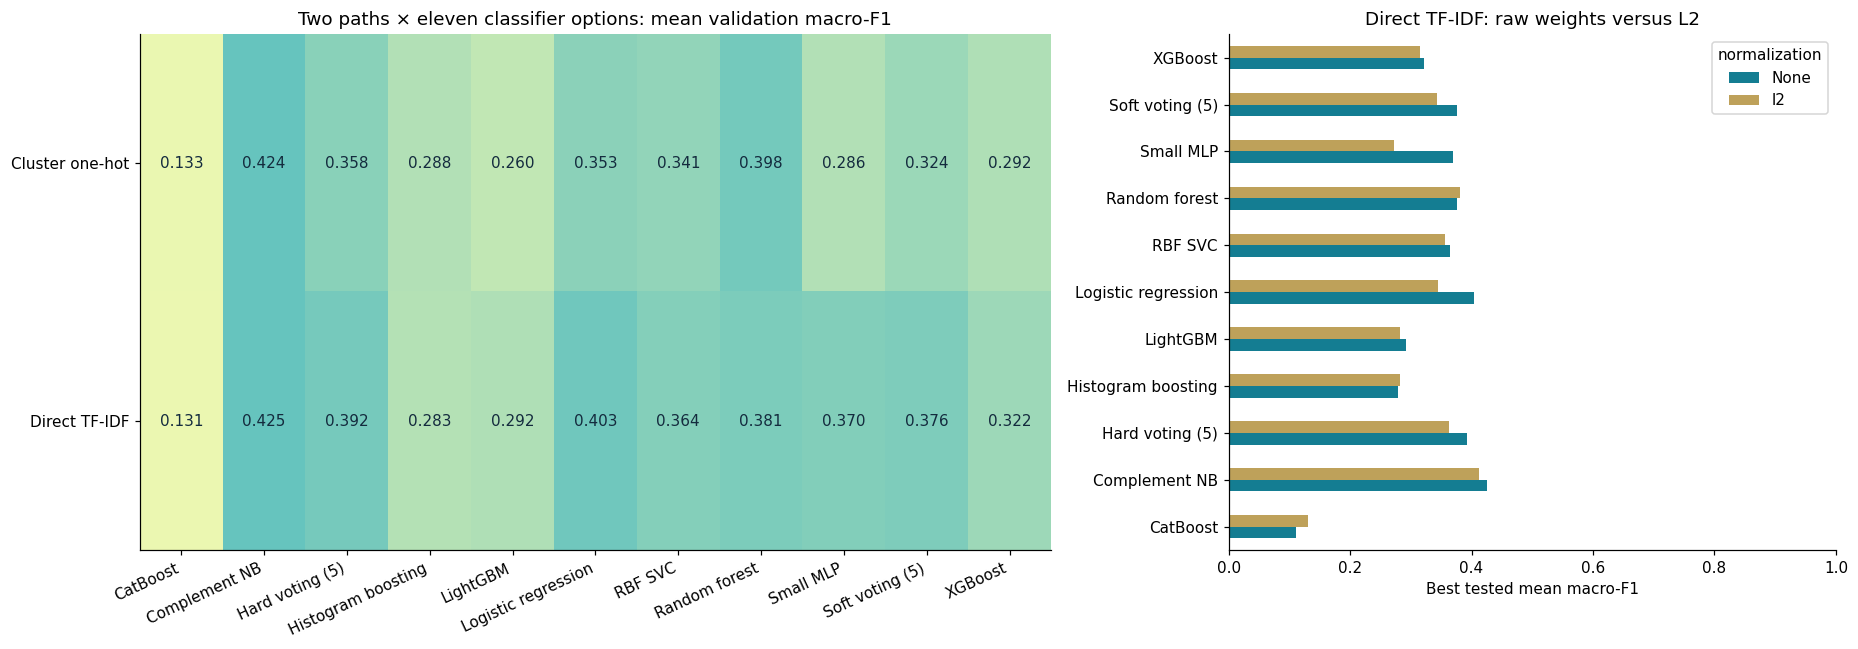

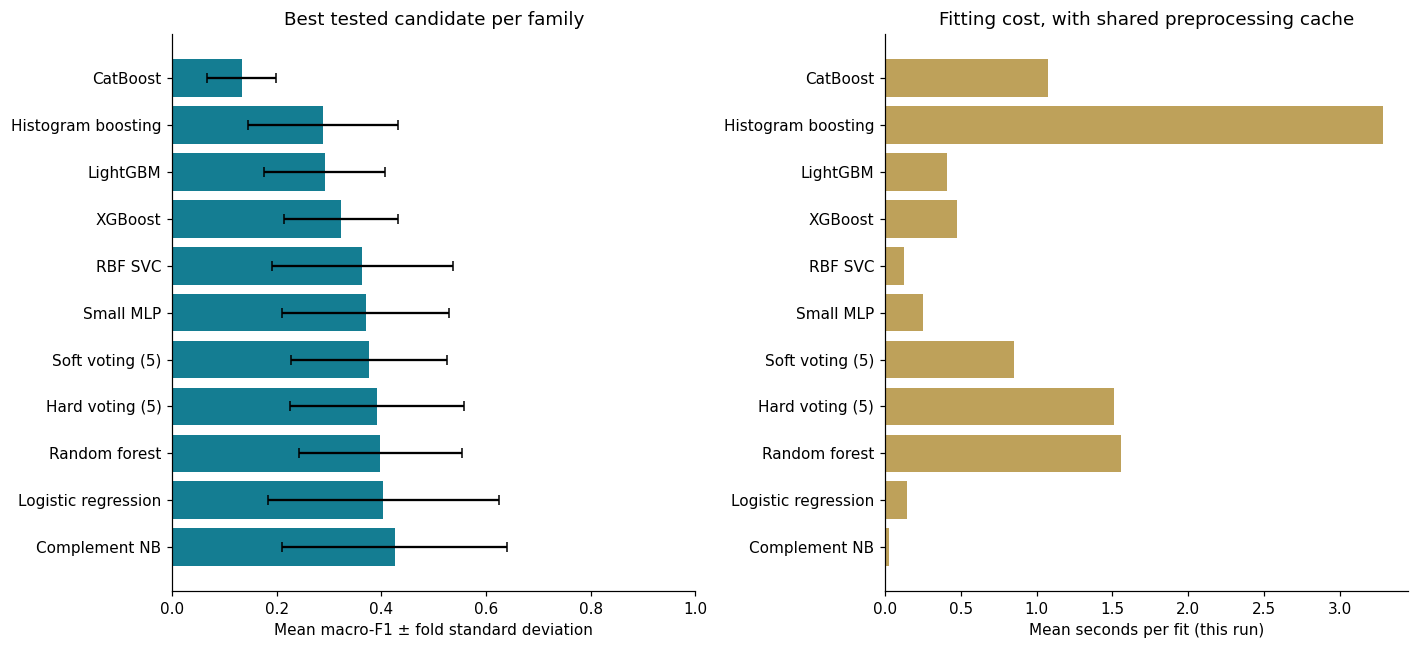

,path,family,normalization,parameters,mean_test_macro_f1
36,Direct TF-IDF,Complement NB,None,"{""classifier__alpha"": 0.1}",0.4255
150,Cluster one-hot,Complement NB,l2,"{""classifier__alpha"": 0.1}",0.4237
2,Direct TF-IDF,Logistic regression,None,"{""classifier__C"": 10}",0.4034
120,Cluster one-hot,Random forest,l2,"{""classifier__max_features"": 0.5, ""classifier__min_samples_leaf"": 1}",0.3978
49,Direct TF-IDF,Hard voting (5),None,"{""classifier__forest__min_samples_leaf"": 1, ""classifier__logistic__C"": 1}",0.3921
63,Direct TF-IDF,Random forest,l2,"{""classifier__max_features"": 0.5, ""classifier__min_samples_leaf"": 1}",0.3813
44,Direct TF-IDF,Soft voting (5),None,"{""classifier__forest__min_samples_leaf"": 2, ""classifier__logistic__C"": 10}",0.3759
35,Direct TF-IDF,Small MLP,None,"{""classifier__alpha"": 1}",0.3697
17,Direct TF-IDF,RBF SVC,None,"{""classifier__C"": 10}",0.3637
162,Cluster one-hot,Hard voting (5),l2,"{""classifier__forest__min_samples_leaf"": 1, ""classifier__logistic__C"": 0.1}",0.3576


path,Cluster one-hot,Direct TF-IDF,cluster_minus_direct
family,,,
Small MLP,0.2855,0.3697,-0.0842
Soft voting (5),0.3243,0.3759,-0.0516
Logistic regression,0.3526,0.4034,-0.0508
Hard voting (5),0.3576,0.3921,-0.0345
LightGBM,0.2604,0.2919,-0.0315
XGBoost,0.2916,0.3223,-0.0306
RBF SVC,0.3410,0.3637,-0.0227
Complement NB,0.4237,0.4255,-0.0018
CatBoost,0.1331,0.1313,0.0017


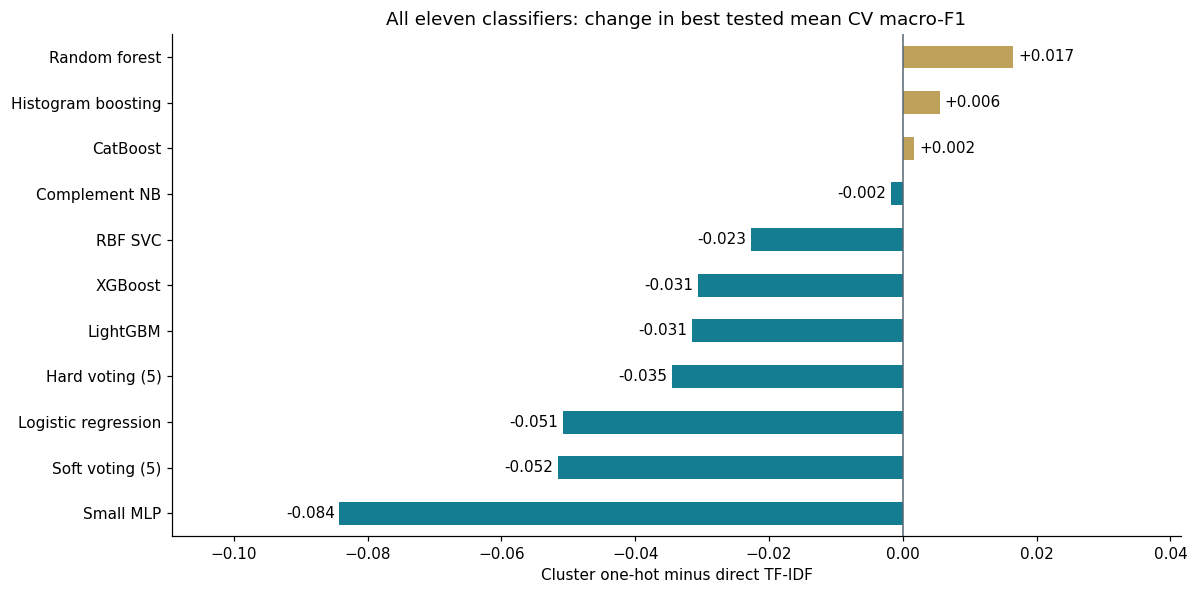

In [12]:
search_results = pd.DataFrame(search.cv_results_)
candidate_results = pd.concat([pd.DataFrame(candidate_descriptions), search_results[[
    'mean_test_macro_f1', 'std_test_macro_f1', 'mean_test_accuracy', 'mean_fit_time', 'rank_test_macro_f1']]], axis=1)
selected_candidate = candidate_results.iloc[search.best_index_]['candidate']
fold_scores = pd.concat([candidate_results[['candidate']], search_results.filter(regex=r'^split\d+_test_')], axis=1)
with pd.option_context('display.max_rows', None):
    display(candidate_results.round(4))
print('Selected before test prediction:', selected_candidate)
main_results = candidate_results.query('experiment == "Main comparison" and family != "Most frequent"')
best_pairs = main_results.sort_values('mean_test_macro_f1', ascending=False, kind='stable').drop_duplicates(['path', 'family'])
comparison_matrix = best_pairs.pivot(index='path', columns='family', values='mean_test_macro_f1')
figure, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={'width_ratios': [1.5, 1]})
heatmap = axes[0].imshow(comparison_matrix, vmin=0, vmax=1, cmap='YlGnBu', aspect='auto')
axes[0].set_xticks(range(len(comparison_matrix.columns)), comparison_matrix.columns, rotation=25, ha='right')
axes[0].set_yticks(range(len(comparison_matrix)), comparison_matrix.index)
for row_number in range(len(comparison_matrix)):
    for column_number in range(len(comparison_matrix.columns)):
        value = comparison_matrix.iloc[row_number, column_number]
        axes[0].text(column_number, row_number, f'{value:.3f}', ha='center', va='center',
                     color='white' if value > 0.55 else '#142b3e')
axes[0].set_title('Two paths × eleven classifier options: mean validation macro-F1')
normalization_comparison = main_results.query('path == "Direct TF-IDF"').groupby(['family', 'normalization']).mean_test_macro_f1.max().unstack()
normalization_comparison.plot.barh(ax=axes[1], color=['#147d92', '#bea15a'])
axes[1].set(xlim=(0, 1), xlabel='Best tested mean macro-F1', ylabel='', title='Direct TF-IDF: raw weights versus L2')
figure.tight_layout()
figure.savefig(OUTPUT_DIRECTORY / 'all_models_and_paths.png', dpi=160)
plt.show()

best_families = main_results.sort_values('mean_test_macro_f1', ascending=False, kind='stable').drop_duplicates('family')
figure, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].barh(best_families.family, best_families.mean_test_macro_f1,
    xerr=best_families.std_test_macro_f1, color='#147d92', capsize=3)
axes[0].set(xlabel='Mean macro-F1 ± fold standard deviation', title='Best tested candidate per family', xlim=(0, 1))
axes[1].barh(best_families.family, best_families.mean_fit_time, color='#bea15a')
axes[1].set(xlabel='Mean seconds per fit (this run)', title='Fitting cost, with shared preprocessing cache')
figure.tight_layout()
figure.savefig(OUTPUT_DIRECTORY / 'model_quality_and_cost.png', dpi=160)
plt.show()
display(best_pairs[['path', 'family', 'normalization', 'parameters', 'mean_test_macro_f1']].round(4))

# Compare every model family across the two paths using the same validation folds.
path_changes = comparison_matrix.T.copy()
path_changes['cluster_minus_direct'] = path_changes['Cluster one-hot'] - path_changes['Direct TF-IDF']
path_changes = path_changes.sort_values('cluster_minus_direct')
display(path_changes.round(4))
figure, axis = plt.subplots(figsize=(11, 5.5))
path_changes.cluster_minus_direct.plot.barh(ax=axis,
    color=np.where(path_changes.cluster_minus_direct.gt(0), '#bea15a', '#147d92'))
axis.axvline(0, color='#536774', linewidth=1)
axis.bar_label(axis.containers[0], fmt='%+.3f', padding=3, fontsize=10)
axis.set(xlabel='Cluster one-hot minus direct TF-IDF', ylabel='',
    title='All eleven classifiers: change in best tested mean CV macro-F1',
    xlim=(path_changes.cluster_minus_direct.min()-0.025, path_changes.cluster_minus_direct.max()+0.025))
figure.tight_layout()
figure.savefig(OUTPUT_DIRECTORY / 'model_path_changes.png', dpi=160)
plt.show()
path_changes.to_csv(OUTPUT_DIRECTORY / 'model_path_changes.csv', encoding='utf-8-sig')

ensemble_defaults = {'classifier__logistic__C': 1, 'classifier__forest__min_samples_leaf': 1}
ensemble_reference_candidates = main_results.loc[
    main_results.family.str.contains('voting') & main_results.parameters.map(lambda value: json.loads(value) == ensemble_defaults)]
chosen_ensemble_rows = best_pairs.loc[best_pairs.family.str.contains('voting')]
ensemble_default_rows = ensemble_reference_candidates.merge(
    chosen_ensemble_rows[['family', 'path', 'normalization']], on=['family', 'path', 'normalization'])


## 12. תחזיות הבדיקה מחברות את ההשוואה לרשומות עצמן
כדי להראות מה כל בחירה משנה בפועל, מאמנים את המועמד שנבחר ב-CV לכל משפחה ולכל מסלול על אותו חלק אימון ומפיקים תחזיות לאותן רשומות בדיקה. הזוכה בכל מסלול והזוכה הכולל נקבעים מראש לפי הוולידציה. לא מחליפים אותם לפי תוצאות הבדיקה. נשמרות כל התחזיות, ובמחברת מוצגת במלואה טבלת הזוכה הכולל.

Accuracy ו-macro-F1 מודדים כאן התאמה לסימול הידני שבקובץ, ולא אמת מקצועית. מחלקות שלא הופיעו באימון נשארות במכנה. Top-3 מדגים עזרה אפשרית לסמלן ואינו שקול לסימול מלא נכון. ציוני ההסתברות אינם מכוילים, ולכן אין מהם סף אוטומציה מוסמך.

כדי לתמוך גם במועמד hard, טבלאות ההצעות מאפשרות הסתברות חסרה. תחזית המחלקה מגיעה מ-predict של הספרייה. רק מודלים המספקים predict_proba מקבלים הסתברויות ו-top-3. אין מימוש ידני של צירוף הקולות.


כדי לפרש את הכוונון בלי להניח שהוא תמיד משפר, משווים גם לברירות המחדל של שני הפרמטרים שנבדקו. בהצבעה קשה ישירה נבחרו C=1 ועלה בגודל 1, בדיוק נקודת הייחוס. בהצבעה רכה השיפור ב-CV היה כ-0.020 במסלול הישיר וכ-0.011 בקבוצות. בבדיקה, כוונון ההצבעה הרכה הישירה שינה macro-F1 מ-0.381 ל-0.385, ובמסלול הקבוצות לא שינה אותו. גם בהצבעה הקשה עם קבוצות לא השתנה ציון הבדיקה. שיפור בקריטריון הבחירה אינו מבטיח שיפור מחוץ לאימון.


/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,path,family,normalization,mean_test_macro_f1,accuracy,macro_f1
5,Direct TF-IDF,Complement NB,None,0.4255,0.6571,0.3545
22,Cluster one-hot,Complement NB,l2,0.4237,0.6286,0.3704


,candidate,ID,source_code,predicted_code,seen_in_training,ranking_score_kind,top_three,top_three_matches_source,matches_source
175,C036,1,2120,2120,True,uncalibrated_probability,"2120, 1330, 3211",True,True
176,C036,3,3512,7126,True,uncalibrated_probability,"7126, 2631, 5223",False,False
177,C036,7,3122,3122,True,uncalibrated_probability,"3122, 2512, 9329",True,True
178,C036,8,2512,2512,True,uncalibrated_probability,"2512, 3122, 3512",True,True
179,C036,25,3323,5322,False,uncalibrated_probability,"5322, 2655, 2631",False,False
180,C036,30,9211,9211,True,uncalibrated_probability,"9211, 5142, 8183",True,True
181,C036,32,2120,2120,True,uncalibrated_probability,"2120, 1330, 3211",True,True
182,C036,36,5322,5322,True,uncalibrated_probability,"5322, 5120, 5142",True,True
183,C036,41,2514,2511,True,uncalibrated_probability,"2511, 2514, 2512",True,False
184,C036,43,2631,2631,True,uncalibrated_probability,"2631, 3211, 3311",True,True


,precision,recall,f1-score,support
1212,0.000000,0.000000,0.000000,1.000000
2113,0.000000,0.000000,0.000000,1.000000
2120,0.666667,1.000000,0.800000,2.000000
2131,0.000000,0.000000,0.000000,0.000000
2142,0.000000,0.000000,0.000000,1.000000
2423,0.000000,0.000000,0.000000,0.000000
2511,0.000000,0.000000,0.000000,0.000000
2512,1.000000,1.000000,1.000000,5.000000
2514,0.000000,0.000000,0.000000,1.000000
2631,0.500000,1.000000,0.666667,1.000000


,EzoAvoda,TeurPeula,TeurTafkid,SemelMishlachSofi,predicted_code,seen_in_training
ID,,,,,,
3,נותנת תמיכה ללקוחות שמבקשים עזרה,מסבירה איך להשתמש בשירותים ממשלתיים באתר האינטרנט,NaN,3512,7126,True
25,מטפל בהזמנות של ציוד שונה להצגות,NaN,NaN,3323,5322,False
41,מתכנת,NaN,NaN,2514,2511,True
66,נותנת תמיכה ללקוחות שמבקשים עזרה,מסבירה איך להשתמש בשירותים ממשלתיים באתר האינטרנט,NaN,3512,7126,True
88,מטפל בהזמנות של ציוד שונה להצגות,NaN,NaN,3323,5322,False
97,תכנון צינורות,NaN,NaN,2142,7126,True
117,חוקר במעבדה,NaN,NaN,2113,2131,False
139,מנהלת משאבי אנוש,מנהלת משאבי אנוש של עובדיםן בישראל,מנהלת משאבי אנוש של עובדיםן בישראל,1212,2423,False
163,קופאי,NaN,NaN,5230,5222,True


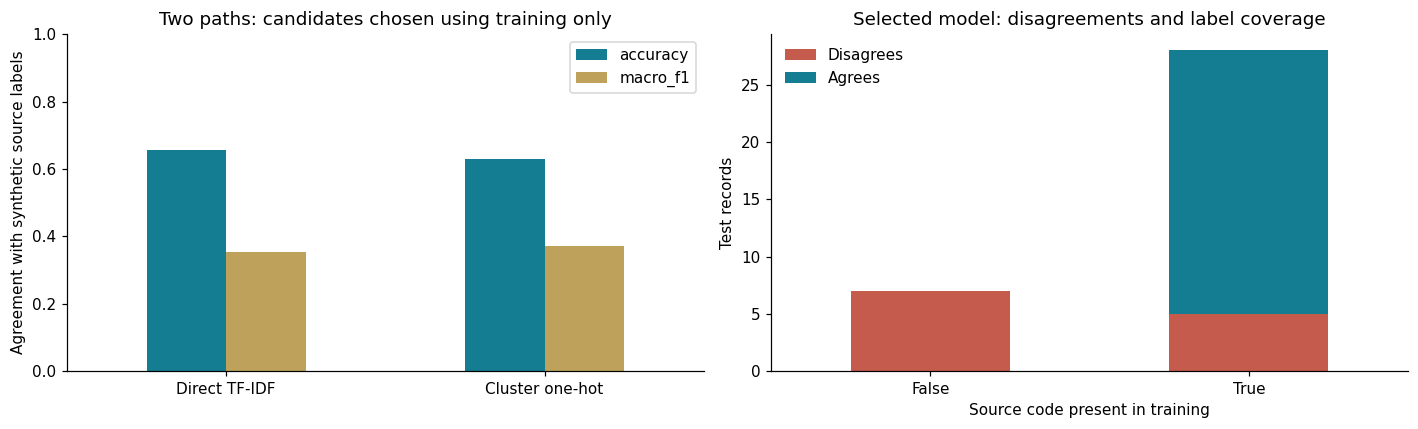

,family,path,normalization,setting,parameters,mean_test_macro_f1,accuracy,macro_f1
7,Soft voting (5),Direct TF-IDF,None,CV selected,"{""classifier__forest__min_samples_leaf"": 2, ""classifier__logistic__C"": 10}",0.3759,0.6571,0.3849
8,Hard voting (5),Direct TF-IDF,None,CV selected,"{""classifier__forest__min_samples_leaf"": 1, ""classifier__logistic__C"": 1}",0.3921,0.6571,0.3716
24,Soft voting (5),Cluster one-hot,l2,CV selected,"{""classifier__forest__min_samples_leaf"": 2, ""classifier__logistic__C"": 10}",0.3243,0.6857,0.4458
25,Hard voting (5),Cluster one-hot,l2,CV selected,"{""classifier__forest__min_samples_leaf"": 1, ""classifier__logistic__C"": 0.1}",0.3576,0.6571,0.4160
6,Soft voting (5),Direct TF-IDF,None,Tuned-parameter defaults,"{""classifier__forest__min_samples_leaf"": 1, ""classifier__logistic__C"": 1}",0.3563,0.6571,0.3809
8,Hard voting (5),Direct TF-IDF,None,Tuned-parameter defaults,"{""classifier__forest__min_samples_leaf"": 1, ""classifier__logistic__C"": 1}",0.3921,0.6571,0.3716
23,Soft voting (5),Cluster one-hot,l2,Tuned-parameter defaults,"{""classifier__forest__min_samples_leaf"": 1, ""classifier__logistic__C"": 1}",0.3138,0.6857,0.4458
26,Hard voting (5),Cluster one-hot,l2,Tuned-parameter defaults,"{""classifier__forest__min_samples_leaf"": 1, ""classifier__logistic__C"": 1}",0.3556,0.6571,0.4160


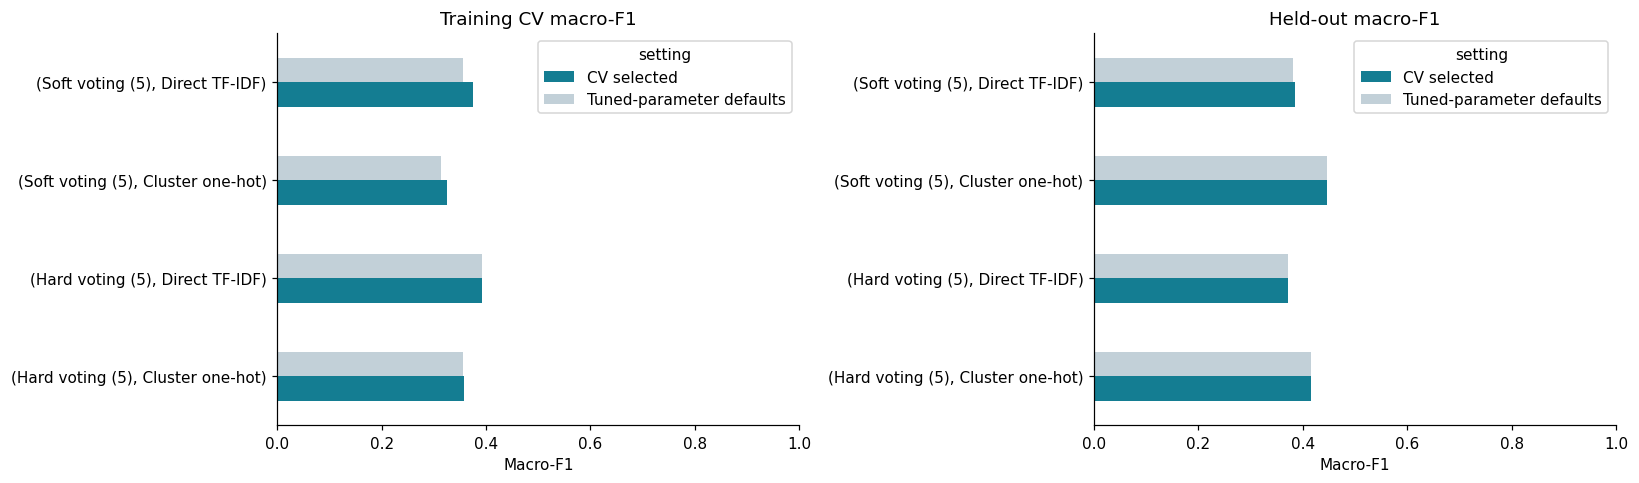

In [13]:
def prediction_scores(fitted_pipeline, inputs):
    if hasattr(fitted_pipeline, 'predict_proba'):
        return fitted_pipeline.predict_proba(inputs), 'uncalibrated_probability'
    return None, 'not_available'

test_result_records, test_prediction_records = [], []
test_candidate_indices = sorted(set(best_pairs.index) | {search.best_index_, len(candidate_results) - 1} | set(ensemble_reference_candidates.index))
for candidate_index in test_candidate_indices:
    candidate = candidate_results.iloc[candidate_index].candidate
    parameters = search_results.params.iloc[candidate_index]
    fitted_candidate = clone(model_pipeline).set_params(**clone(parameters, safe=False)).fit(training_features, training_codes)
    predicted_codes = np.asarray(fitted_candidate.predict(test_features)).ravel()
    test_result_records.append({'candidate': candidate, 'accuracy': accuracy_score(test_codes, predicted_codes),
        'macro_f1': f1_score(test_codes, predicted_codes, average='macro', zero_division=0)})
    test_prediction_records.extend({'candidate': candidate, 'ID': int(labeled_record_ids.iloc[position]),
        'source_code': source_code, 'predicted_code': predicted_code, 'seen_in_training': source_code in set(training_codes)}
        for position, source_code, predicted_code in zip(test_positions, test_codes, predicted_codes))
test_results = candidate_results.merge(pd.DataFrame(test_result_records), on='candidate', validate='one_to_one')
all_test_predictions = pd.DataFrame(test_prediction_records)
best_path_candidates = main_results.sort_values('mean_test_macro_f1', ascending=False, kind='stable').drop_duplicates('path')
path_comparison = test_results.loc[test_results.candidate.isin(best_path_candidates.candidate)].copy()
display(path_comparison[['path', 'family', 'normalization', 'mean_test_macro_f1', 'accuracy', 'macro_f1']].round(4))

selected_test_predictions = all_test_predictions.query('candidate == @selected_candidate').copy()
test_scores, test_score_kind = prediction_scores(search.best_estimator_, test_features)
test_top_three = (search.best_estimator_.classes_[np.argsort(-test_scores, axis=1, kind='stable')[:, :3]]
                  if test_scores is not None else [[] for _ in range(len(test_features))])
selected_test_predictions['ranking_score_kind'] = test_score_kind
selected_test_predictions['top_three'] = [', '.join(codes) for codes in test_top_three]
selected_test_predictions['top_three_matches_source'] = [code in suggestions if len(suggestions) else pd.NA for code, suggestions in zip(test_codes, test_top_three)]
selected_test_predictions['matches_source'] = selected_test_predictions.source_code.eq(selected_test_predictions.predicted_code)
with pd.option_context('display.max_rows', None):
    display(selected_test_predictions)
per_class_results = pd.DataFrame(classification_report(test_codes, selected_test_predictions.predicted_code,
    output_dict=True, zero_division=0)).T
display(per_class_results)
error_context = survey_records.set_index('ID').loc[selected_test_predictions.loc[
    ~selected_test_predictions.matches_source, 'ID'], ['EzoAvoda', 'TeurPeula', 'TeurTafkid', TARGET_FIELD]]
display(error_context.join(selected_test_predictions.set_index('ID')[['predicted_code', 'seen_in_training']]))

figure, axes = plt.subplots(1, 2, figsize=(13, 4))
path_comparison.set_index('path')[['accuracy', 'macro_f1']].plot.bar(ax=axes[0], rot=0, color=['#147d92', '#bea15a'])
axes[0].set(ylim=(0, 1), ylabel='Agreement with synthetic source labels', xlabel='', title='Two paths: candidates chosen using training only')
error_breakdown = selected_test_predictions.groupby(['seen_in_training', 'matches_source']).size().unstack(fill_value=0).reindex(columns=[False, True], fill_value=0)
error_breakdown.plot.bar(stacked=True, ax=axes[1], rot=0, color=['#c45b4d', '#147d92'])
axes[1].set(xlabel='Source code present in training', ylabel='Test records', title='Selected model: disagreements and label coverage')
axes[1].legend(['Disagrees', 'Agrees'], frameon=False)
figure.tight_layout()
figure.savefig(OUTPUT_DIRECTORY / 'two_paths_test_results.png', dpi=160)
plt.show()
ensemble_tuning_comparison = pd.concat([
    test_results.loc[test_results.candidate.isin(chosen_ensemble_rows.candidate)].assign(setting='CV selected'),
    test_results.loc[test_results.candidate.isin(ensemble_default_rows.candidate)].assign(setting='Tuned-parameter defaults')])
display(ensemble_tuning_comparison[['family', 'path', 'normalization', 'setting', 'parameters',
    'mean_test_macro_f1', 'accuracy', 'macro_f1']].round(4))
figure, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for axis, metric, title in zip(axes, ['mean_test_macro_f1', 'macro_f1'], ['Training CV macro-F1', 'Held-out macro-F1']):
    ensemble_tuning_comparison.pivot(index=['family', 'path'], columns='setting', values=metric).plot.barh(
        ax=axis, color=['#147d92', '#c2d0d8'])
    axis.set(title=title, xlabel='Macro-F1', ylabel='', xlim=(0, 1))
figure.tight_layout()
figure.savefig(OUTPUT_DIRECTORY / 'ensemble_defaults_and_tuning.png', dpi=160)
plt.show()


## 13. בדיקת החלוקה מסבירה מה יכול לנפח ציון
כדי לבדוק את משמעות התיאורים החוזרים, משווים חלוקה אקראית לפי שורה לחלוקה לפי קבוצות תיאור, עם אותו מסווג ליניארי ואותו TF-IDF גולמי. זהו ניסוי אבחוני קבוע שאינו משתתף בבחירת המודל. סופרים גם חפיפת תיאורים ומחלקות שלא נראו באימון.

הפלט מאפשר לזהות עד כמה חלוקה לפי שורות מקלה על המשימה. ההפרש בציונים אינו אומדן סיבתי טהור של זליגה: גם כיסוי המקצועות והרכב הקפלים משתנים. אין כאן הוכחה שהרשומות החוזרות הן שידורים של אותו אדם.

/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/model_selection/_split.py:87: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


,split,accuracy,macro_f1,records_with_description_overlap,records_with_unseen_labels
0,Random rows,0.811518,0.509143,115,26
1,Description groups,0.586387,0.308805,0,59


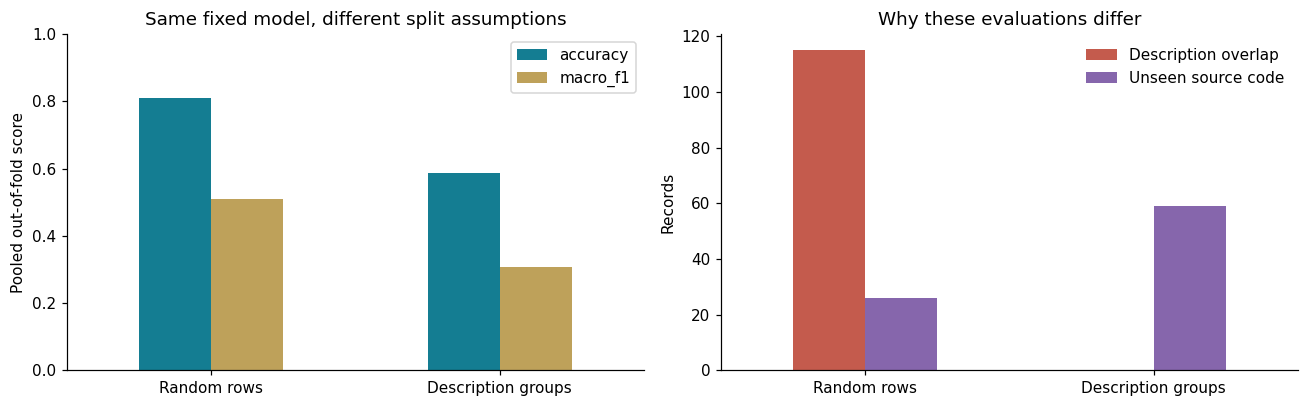

In [14]:
split_comparison_records = []
for split_name, splitter in [
    ('Random rows', KFold(n_splits=10, shuffle=True, random_state=RANDOM_SEED)),
    ('Description groups', GroupKFold(n_splits=10, shuffle=True, random_state=RANDOM_SEED))]:
    partitions = list(splitter.split(labeled_inputs, occupation_codes, labeled_groups))
    reference_model = Pipeline([('features', build_preprocessor()), ('classifier', clone(logistic_model))])
    predictions = cross_val_predict(reference_model, labeled_inputs, occupation_codes, cv=partitions, n_jobs=1)
    overlapping_records = sum(labeled_groups.iloc[validation].isin(labeled_groups.iloc[training]).sum()
                              for training, validation in partitions)
    unseen_records = sum((~occupation_codes.iloc[validation].isin(occupation_codes.iloc[training])).sum()
                         for training, validation in partitions)
    split_comparison_records.append({'split': split_name, 'accuracy': accuracy_score(occupation_codes, predictions),
        'macro_f1': f1_score(occupation_codes, predictions, average='macro', zero_division=0),
        'records_with_description_overlap': int(overlapping_records), 'records_with_unseen_labels': int(unseen_records)})
split_comparison = pd.DataFrame(split_comparison_records)
display(split_comparison)
figure, axes = plt.subplots(1, 2, figsize=(12, 3.8))
split_comparison.set_index('split')[['accuracy', 'macro_f1']].plot.bar(ax=axes[0], rot=0, color=['#147d92', '#bea15a'])
axes[0].set(ylim=(0, 1), xlabel='', ylabel='Pooled out-of-fold score', title='Same fixed model, different split assumptions')
split_comparison.set_index('split')[['records_with_description_overlap', 'records_with_unseen_labels']].plot.bar(
    ax=axes[1], rot=0, color=['#c45b4d', '#8666ac'])
axes[1].set(xlabel='', ylabel='Records', title='Why these evaluations differ')
axes[1].legend(['Description overlap', 'Unseen source code'], frameon=False)
figure.tight_layout()
figure.savefig(OUTPUT_DIRECTORY / 'split_sensitivity.png', dpi=160)
plt.show()

## 14. אימון סופי והצעות לרשומות עם סימול חלקי
כדי להפיק את תוצר המשימה לאחר ההשוואה, מאמנים את המפרט שנבחר על כל 191 הרשומות בעלות קוד מלא. תשע הרשומות עם `X` אינן תוויות אימון מלאות, ולכן מקבלות הצעות נפרדות. הספרות הידועות בקוד החלקי אינן מאפייני חיזוי. הן משמשות רק להצגת הצעה נוספת התואמת אותן, אם קיימת מחלקת אימון מתאימה.

הפלט שומר את הקוד המקורי, התחזית, שלוש הצעות ודגל לחוסר תיאור ענייני. התאמה לספרות הידועות אינה אישור מקצועי, והצעה בהיעדר תיאור אינה מקבלת סמכות אוטומטית. כל הרשומות האלה מועברות לבדיקה אנושית. גם הקודים המלאים אינם "אמת נקייה". לא מתקנים אותם על פי תחזית המודל.

In [15]:
final_model = clone(search.best_estimator_).set_params(memory=None).fit(labeled_inputs, occupation_codes)
partial_records = survey_records.loc[partial_labels]
partial_inputs = model_inputs.loc[partial_labels]
partial_scores, partial_score_kind = prediction_scores(final_model, partial_inputs)
partial_codes = np.asarray(final_model.predict(partial_inputs)).ravel()
trained_codes = final_model.classes_
partial_prediction_records = []
for record, scores, predicted_code in zip(partial_records.itertuples(), partial_scores if partial_scores is not None else [None] * len(partial_records), partial_codes):
    original_code = getattr(record, TARGET_FIELD)
    ordered_classes = np.argsort(-scores, kind='stable') if scores is not None else np.array([], dtype=int)
    compatible_classes = np.array([all(original == 'X' or original == proposed
        for original, proposed in zip(original_code, code)) for code in trained_codes])
    compatible_order = ordered_classes[compatible_classes[ordered_classes]]
    partial_prediction_records.append({'ID': record.ID, 'original_partial_code': original_code,
        'predicted_code': predicted_code, 'top_three': ', '.join(trained_codes[ordered_classes[:3]]),
        'maximum_score': float(scores.max()) if scores is not None else None, 'score_kind': partial_score_kind,
        'digit_compatible_suggestion': trained_codes[compatible_order[0]] if len(compatible_order) else None,
        'compatible_training_classes': int(compatible_classes.sum()),
        'no_substantive_description': not bool(has_description.loc[record.Index]), 'action': 'human_review'})
partial_predictions = pd.DataFrame(partial_prediction_records)
display(partial_predictions)
assert len(partial_predictions) == 9 and set(trained_codes) == set(occupation_codes)
if partial_scores is not None:
    assert np.isfinite(partial_scores).all() and np.allclose(partial_scores.sum(axis=1), 1)

,ID,original_partial_code,predicted_code,top_three,maximum_score,score_kind,digit_compatible_suggestion,compatible_training_classes,no_substantive_description,action
0,18,1XXX,2120,"2120, 5120, 3211",0.026891,uncalibrated_probability,1345,4,True,human_review
1,45,XXXX,2411,"2411, 2423, 2511",0.093802,uncalibrated_probability,2411,59,True,human_review
2,50,1XXX,2120,"2120, 5120, 3211",0.026891,uncalibrated_probability,1345,4,True,human_review
3,81,1XXX,5120,"5120, 5131, 2120",0.026714,uncalibrated_probability,1345,4,True,human_review
4,108,XXXX,2411,"2411, 2423, 2511",0.092300,uncalibrated_probability,2411,59,True,human_review
5,113,1XXX,2120,"2120, 2511, 2514",0.022458,uncalibrated_probability,1345,4,True,human_review
6,142,XXXX,9112,"9112, 5230, 2423",0.927829,uncalibrated_probability,9112,59,False,human_review
7,165,335X,3354,"3354, 4211, 3512",1.000000,uncalibrated_probability,3354,1,False,human_review
8,193,XXXX,3354,"3354, 3512, 7126",1.000000,uncalibrated_probability,3354,59,False,human_review


### רשומה חדשה מדגימה אנסמבל רך ואנסמבל קשה
כדי להשוות שימוש בשתי שיטות ההצבעה, בוחרים לכל אחת את המפרט הטוב ב-CV ומאמנים אנסמבל חדש על כל התוויות המלאות. בדיקת זהות מוודאת שהרכיבים המאומנים שונים ממפרטי הבנייה, ושמופעי soft ו-hard אינם משותפים. שניהם חוזים את אותה רשומה חדשה שנכתבה להדגמה. אין לה קוד אמת ולכן אין מדד דיוק.

דירוג soft מבוסס על הסתברויות בלתי מכוילות. ל-hard מוצגת תחזית המחלקה בלבד. הספרייה אינה מספקת לו predict_proba, ולכן אין עבורו הסתברויות או דירוג top-3. הקוד אינו משתמש בקוד ענף סופי, במזהה או בתווית בזמן החיזוי. בדיקות הקצה בהמשך בודקות תקינות קלט בלבד.


In [16]:
new_record = pd.DataFrame([{field: None for field in INPUT_FIELDS}])
new_record.loc[0, ['YeshuvAvoda', 'ShemAvoda', 'SugAvoda', 'EzoAvoda', 'TeurPeula', 'TeurTafkid']] = [
    'חיפה', 'חברת תוכנה חדשה', 'פיתוח תוכנה', 'מפתחת תוכנה', 'כתיבת קוד ובדיקת תוכנה', 'מפתחת']
new_record.loc[0, ['MaamadAvoda', 'MakorSachar', 'TeudaGvoha', 'shnotlimud', 'Gil', 'TarichHathala']] = [
    1, 1, 5, 16, 30, '2024-01-01']

fitted_ensembles, demonstration_records = {}, []
for ensemble_name in ['Soft voting (5)', 'Hard voting (5)']:
    ensemble_index = main_results.loc[main_results.family.eq(ensemble_name), 'mean_test_macro_f1'].idxmax()
    configuration = candidate_results.iloc[ensemble_index]
    normalization = None if configuration.normalization == 'None' else configuration.normalization
    ensemble = Pipeline([('features', build_preprocessor(configuration.path, normalization)),
                         ('classifier', build_ensemble('soft' if ensemble_name.startswith('Soft') else 'hard'))])
    ensemble.set_params(**json.loads(configuration.parameters)).fit(labeled_inputs, occupation_codes)
    fitted_ensembles[ensemble_name] = ensemble
    voters = ensemble.named_steps['classifier']
    assert all(trained is not specification for trained, (_, specification) in zip(voters.estimators_, voters.estimators))
    prepared_record = prepare_model_inputs(new_record)
    predicted_code = np.asarray(ensemble.predict(prepared_record)).ravel()[0]
    scores, score_kind = prediction_scores(ensemble, prepared_record)
    ranked_classes = np.argsort(-scores[0], kind='stable')[:3] if scores is not None else np.array([], dtype=int)
    demonstration_records.append({'ensemble': ensemble_name, 'candidate': configuration.candidate,
        'path': configuration.path, 'predicted_code': predicted_code,
        'top_three': ', '.join(ensemble.classes_[ranked_classes]) or None,
        'maximum_probability': float(scores[0].max()) if scores is not None else None,
        'probability_available': scores is not None})
assert all(soft is not hard for soft, hard in zip(
    fitted_ensembles['Soft voting (5)'].named_steps['classifier'].estimators_,
    fitted_ensembles['Hard voting (5)'].named_steps['classifier'].estimators_))
new_instance_prediction = pd.DataFrame(demonstration_records)
display(new_record)
display(new_instance_prediction)


,YeshuvAvoda,ShemAvoda,SugAvoda,ShemMachlaka,SugMachlaka,EzoAvoda,TeurPeula,TeurTafkid,MenahelEtMi,MaamadAvoda,MakorSachar,TeudaGvoha,shnotlimud,Gil,TarichHathala
0,חיפה,חברת תוכנה חדשה,פיתוח תוכנה,None,None,מפתחת תוכנה,כתיבת קוד ובדיקת תוכנה,מפתחת,None,1,1,5,16,30,2024-01-01


,ensemble,candidate,path,predicted_code,top_three,maximum_probability,probability_available
0,Soft voting (5),C044,Direct TF-IDF,2512,"2512, 2514, 4413",0.58389,True
1,Hard voting (5),C049,Direct TF-IDF,2512,None,NaN,False


## 15. בדיקות שימוש ותוצרים שניתן לשחזר
כדי לוודא שהפתרון מתמודד עם סוגי הקלט שהמטלה מתירה, בודקים חיזוי עם תשובות חסרות, קטגוריה חדשה, קוד לא תקין, תאריך לא ניתן לפענוח וטקסט שלא נצפה. זו בדיקת תקינות, לא הוכחת איכות חיזוי. פונקציית ההכנה זהה באימון ובשימוש.

לאחר מכן שומרים את כל הטבלאות, שתי מטריצות ההמחשה עם שמות המאפיינים ומזהי השורות, ואת מפרט ההרצה. המודל השמור משמש לשחזור בתוך סביבת המחברת שבה מוגדר המתאם. הוא אינו חבילת ייצור עצמאית. אין לטעון קובץ joblib ממקור לא מוכר. הפלט מאפשר לבודק להתחקות אחר כל מספר וכל תחזית, מתוך קובץ המקור והחישובים שבמחברת.

In [17]:
probe_records = survey_records.head(3).copy()
probe_records.loc[probe_records.index[0], INPUT_FIELDS] = np.nan
probe_records.loc[probe_records.index[1], 'MenahelEtMi'] = 99
probe_records.loc[probe_records.index[1], 'YeshuvAvoda'] = 'יישוב שלא הופיע באימון'
probe_records.loc[probe_records.index[2], 'TarichHathala'] = 'not a date'
probe_records.loc[probe_records.index[2], TEXT_FIELDS] = 'unseenwordxyz'
for preparation in [build_preprocessor(), build_preprocessor('Cluster one-hot')]:
    preparation.fit(prepare_model_inputs(probe_records.iloc[[0]]))
    assert np.isfinite(preparation.transform(prepare_model_inputs(probe_records))).all()
probe_predictions = final_model.predict(prepare_model_inputs(probe_records))
assert len(probe_predictions) == 3
joblib.dump(final_model, OUTPUT_DIRECTORY / 'occupation_model.joblib')
restored_model = joblib.load(OUTPUT_DIRECTORY / 'occupation_model.joblib')
assert np.array_equal(np.asarray(restored_model.predict(partial_inputs)).ravel(), partial_codes)
assert hashlib.sha256(source_bytes).hexdigest() == SOURCE_SHA256

result_tables = {'column_overview': column_overview.reset_index(), 'source_issues': source_issues,
    'all_source_values': all_value_counts, 'data_quality_counts': data_quality_counts.reset_index(),
    'class_support': class_support.reset_index(), 'fold_overview': fold_overview,
    'representation_overview': representation_overview, 'all_cluster_counts': cluster_search_results,
    'cluster_memberships': pd.DataFrame(cluster_memberships).drop_duplicates(),
    'all_candidate_results': candidate_results, 'all_candidate_fold_scores': fold_scores,
    'all_test_results': test_results, 'all_test_predictions': all_test_predictions,
    'selected_test_predictions': selected_test_predictions, 'per_class_results': per_class_results.reset_index(),
    'two_path_comparison': path_comparison, 'split_comparison': split_comparison, 'partial_predictions': partial_predictions, 'new_instance_prediction': new_instance_prediction, 'ensemble_tuning_comparison': ensemble_tuning_comparison}
for name, table in result_tables.items():
    table.to_csv(OUTPUT_DIRECTORY / f'{name}.csv', index=False, encoding='utf-8-sig')
raw_tfidf_sample.to_csv(OUTPUT_DIRECTORY / 'raw_tfidf_displayed_terms.csv', index=False)
onehot_sample.to_csv(OUTPUT_DIRECTORY / 'cluster_onehot_text_features.csv', index=False)
from scipy.sparse import csr_matrix, save_npz
for name, matrix in [('direct_tfidf', direct_matrix), ('cluster_onehot', cluster_matrix)]:
    save_npz(OUTPUT_DIRECTORY / f'{name}_training_matrix.npz', csr_matrix(matrix))
pd.DataFrame({'ID': labeled_record_ids.iloc[training_positions].to_numpy()}).to_csv(
    OUTPUT_DIRECTORY / 'training_matrix_rows.csv', index=False)
matrix_columns = {
    'direct_tfidf': direct_preview.get_feature_names_out().tolist(),
    'cluster_onehot': [field + '__' + name for field in TEXT_FIELDS
        for name in cluster_preview.named_transformers_[field].named_steps['onehot'].get_feature_names_out(['group'])]
        + ['categories__' + name for name in cluster_preview.named_transformers_['categories'].get_feature_names_out(CATEGORY_FIELDS)]
        + ['numbers__' + name for name in cluster_preview.named_transformers_['numbers'].get_feature_names_out(NUMBER_FIELDS)]}
assert len(matrix_columns['cluster_onehot']) == cluster_matrix.shape[1]
(OUTPUT_DIRECTORY / 'training_matrix_columns.json').write_text(json.dumps(matrix_columns, ensure_ascii=False, indent=2))
run_manifest = {'source_sha256': SOURCE_SHA256, 'seed': RANDOM_SEED, 'python': sys.version.split()[0],
    'sklearn': sklearn.__version__, 'pandas': pd.__version__, 'numpy': np.__version__,
    'external_models': {package: importlib.metadata.version(package) for package in ['xgboost', 'lightgbm', 'catboost']},
    'survey_records': len(survey_records), 'complete_labels': len(occupation_codes), 'partial_labels': len(partial_predictions),
    'training_records': len(training_features), 'test_records': len(test_features), 'folds': len(validation_splits),
    'candidate_count': len(candidate_results), 'selected_candidate': selected_candidate,
    'selected_configuration': candidate_results.iloc[search.best_index_].to_dict(),
    'training_warnings': warning_summary.to_dict(), 'search_seconds': search_seconds,
    'total_seconds': time.perf_counter() - run_started, 'actual_colab_session_tested': False,
    'smoothing': False, 'kmeans_normalization': 'l2', 'kmeans_uses_target_labels': False,
    'description_groups_are_participant_ids': False, 'probabilities_are_calibrated': False,
    'test_is_independent_production_evidence': False}
(OUTPUT_DIRECTORY / 'run_manifest.json').write_text(json.dumps(run_manifest, ensure_ascii=False, indent=2))
print('Checks passed. Saved', len(result_tables), 'result tables, matrices, figures and model.')
print('Total execution seconds:', round(run_manifest['total_seconds'], 1))

Checks passed. Saved 20 result tables, matrices, figures and model.
Total execution seconds: 63.3


## 16. תובנות והמשך הטמעה
כדי לבחור צעד המשך שמבוסס על מה שנלמד, מפרידים בין תקינות התהליך, תוצאות המדגם והבטחת איכות תפעולית. התא הבא מסכם מספרים שחושבו בהרצה, כולל שני המסלולים והבחירה. הישג תפעולי יימדד בהפחתת זמן סימול ובשיעור טעויות מאומת, ולא בציון גבוה על הסימולציה.

מגבלות הנתונים מכוונות את סדר העבודה הבא: לתעד מזהה נסקר ושידור, חותמת זמן ומזהה סמלן. לאמת את ממשק השאלון ואת זמינות קוד הענף. להכין מדגם אמת בבדיקה כפולה ובהכרעת מומחה. להעריך לפי נסקר וזמן. ורק אז לכייל ציונים ולבחור יחס בין כיסוי אוטומטי לטעויות. בתחילת ההטמעה המודל יפעל לצד הסמלנים עם רישום תיקונים, סיבות אי-סימול וניטור חסרים, מקצועות חדשים ושינויי התפלגות.

ההשוואה בין המסלולים בודקת אם grouping שימושי למשימת הסיווג. ציון CH גבוה אינו מוכיח זאת, וייתכן שהאופטימיזציה תיצור כמעט קבוצה לכל ניסוח. באותו אופן, שיפור של מודל מורכב על המדגם אינו מוכיח שהוא מצדיק עלות או סיכון בהטמעה.

### התאמה לתרחיש של אלפים עד מיליון רשומות
כדי שהפתרון יוכל להתקדם מעבר לסימולציה, מבחינים בין רעיון המידול לבין אופן חישובו. גודל הטבלה לבדו אינו קובע את הספרייה: נמדוד גם אורך טקסט, גודל אוצר המילים, מספר הערכים הלא-אפסיים, מספר המקצועות ותמיכה בכל מקצוע.

| רכיב | התאמה שיש לבחון על נתוני אימון מייצגים |
|---|---|
| TF-IDF ישיר | לשמור מטריצות דלילות ולבחון מסווגים שתומכים בהן. בגידול מעבר לזיכרון אפשר לבחון אצוות, HashingVectorizer ומסווג התומך ב-partial_fit, עם בחינה של הפשרה בפרשנות וב-IDF |
| קבוצות | להגביל את חיפוש K בתקציב מנומק, ללמוד על מדגם אימון מייצג או לבחון MiniBatchKMeans, ולשייך רשומות חדשות באצוות. אין להריץ חיפוש עד כל מספר ניסוחים אפשרי על מיליון שורות |
| גודל הייצוג | לבדוק אם K נשאר קטן ביחס למספר הניסוחים. הקטנת מספר מאפייני המסווג אינה מבטלת את עלות TF-IDF ושיוך הקבוצות |
| משפחות המסווגים | לבדוק איכות, זמן אימון, זמן חיזוי וזיכרון בנפרד. RBF SVC, יער גדול והצבעה של חמישה מודלים עלולים להיות יקרים גם אם הם מתאימים למדגם קטן |
| תשתית | לבחון Spark או H2O כאשר פיזור הנתונים, זיכרון או תשתית הארגון מצדיקים זאת. הם לא הורצו בסימולציה, ומיליון רשומות אינן כשלעצמן הוכחה שדרושה מערכת מבוזרת |
| הערכה ותפעול | להפריד נסקרים וזמנים, לשמור קבוצות נדירות בדיווח, למדוד כיסוי וטעויות, ולגרס יחד אוצר מילים, מרכזי קבוצות, קידוד ומסווג |

כאן ההמרה למערכים צפופים מאפשרת להשוות גם ספריות שדורשות אותם על 200 רשומות. זו בחירת מימוש למדגם הנוכחי. במעבר לנפח גדול לא נעתיק המרה זו ללא בדיקת זיכרון. עלות הלמידה, העיבוד והחיזוי חייבת להימדד על עומס מייצג. אין בתוצאות הנוכחיות מדידה של מיליון רשומות או הוכחה שאחד המסלולים עדיף בכל נפח.


### מה מראות התוצאות המצורפות
כדי להבחין בין בחירה לפי כלל מוגדר לבין טענה ליתרון יציב, קוראים את הפערים יחד עם השונות וכיסוי המקצועות.

- Complement NB עם TF-IDF גולמי ו-alpha=0.1 נבחר לפי macro-F1 ממוצע ב-CV של 0.425. אותו מסווג במסלול הקבוצות הגיע ל-0.424. הפער קטן מאוד ביחס לסטיית התקן בין הקפלים, בערך 0.22 בשניהם. אין מכאן הוכחה לעדיפות כללית של אחד הייצוגים.
- ב-35 רשומות הבדיקה המסלול הישיר הגיע ל-accuracy של 0.657 ול-macro-F1 של 0.354. מסלול הקבוצות הגיע ל-0.629 ול-0.370 בהתאמה. המדדים מציגים פשרה, והבחירה שנעשתה ב-CV נשמרת.
- ההצבעה הרכה הגיעה ל-macro-F1 מרבי ב-CV של 0.376, וההצבעה הקשה ל-0.392. אף אחת מהן לא הובילה בניסוי הזה. שילוב מודלים מורכבים אינו תחליף לבדיקה מול בסיס פשוט.
- בניסוי האבחוני עם אותו מודל ליניארי, accuracy היה 0.812 בחלוקת שורות ו-0.586 בחלוקת קבוצות תיאור. בחלוקת השורות היו 115 רשומות עם תיאור שהופיע באימון, לעומת אפס בחלוקה הקבוצתית. גם מספר הרשומות עם מקצוע שלא נצפה באימון השתנה, ולכן אין לייחס את כל ההפרש לחפיפה בלבד.
- בשש מתשע הרשומות עם יעד חלקי אין תיאור ענייני בששת שדות התיאור. תחזית המבוססת על שאר השדות אינה משלימה את המידע החסר. גם ציון הסתברות קרוב ל-1 בחלק מהרשומות אינו אישור מקצועי.


כדי לבדוק אם המסקנה משתנה בנתונים גדולים ומגוונים יותר, נבחן בנפרד כמות רשומות, מספר מקצועות ומגוון ניסוחים. יותר דוגמאות לכל מקצוע עשויות לשפר את שני המסלולים. אשכולות עשויים לעזור כאשר ניסוחים שונים חולקים ראיות לשוניות שימושיות, אך עלולים לאבד מילה נדירה שמבדילה בין מקצועות. TF-IDF אינו מבטיח זיהוי מילים נרדפות או תיקון שגיאות כתיב. יותר שורות לבדן אינן סיבה לצפות ליתרון של הקיבוץ, ודירוג המודלים עשוי להשתנות או להישאר דומה. נבדוק זאת במדגמי אימון גדלים מול בדיקה מייצגת קבועה, תוך מדידת איכות, זיכרון וזמן.


In [18]:
chosen_result = test_results.loc[test_results.candidate.eq(selected_candidate)].iloc[0]
conclusions = pd.DataFrame([
    ['נתונים', f'{len(survey_records)} רשומות. {len(field_definitions)} שדות. {complete_labels.sum()} קודים מלאים ו-{partial_labels.sum()} חלקיים'],
    ['כיסוי מקצועות', f'{len(class_support)} מחלקות. {class_support.records.eq(1).sum()} מחלקות עם רשומה אחת. {class_support.groups.eq(1).sum()} עם קבוצת תיאור אחת'],
    ['בחירה לפי אימון', f'{selected_candidate}: {chosen_result["path"]}, {chosen_result["family"]}, normalization={chosen_result["normalization"]}'],
    ['בדיקה תיאורית', f'accuracy={chosen_result.accuracy:.3f}, macro-F1={chosen_result.macro_f1:.3f}. {len(test_features)} רשומות'],
    ['פעולה', 'כל תשע הרשומות החלקיות מקבלות הצעה לבדיקה אנושית. לא נקבע סף אוטומציה מהסימולציה.']
], columns=['נושא', 'מסקנה'])
display(conclusions)
display(path_comparison[['path', 'family', 'normalization', 'accuracy', 'macro_f1']].round(4))

,נושא,מסקנה
0,נתונים,200 רשומות. 18 שדות. 191 קודים מלאים ו-9 חלקיים
1,כיסוי מקצועות,59 מחלקות. 24 מחלקות עם רשומה אחת. 34 עם קבוצת תיאור אחת
2,בחירה לפי אימון,"C036: Direct TF-IDF, Complement NB, normalization=None"
3,בדיקה תיאורית,"accuracy=0.657, macro-F1=0.354. 35 רשומות"
4,פעולה,כל תשע הרשומות החלקיות מקבלות הצעה לבדיקה אנושית. לא נקבע סף אוטומציה מהסימולציה.


,path,family,normalization,accuracy,macro_f1
5,Direct TF-IDF,Complement NB,None,0.6571,0.3545
22,Cluster one-hot,Complement NB,l2,0.6286,0.3704


## מקורות והקשר העבודה
כדי לאפשר בדיקה של ההחלטות, הרשימה מחברת בין חומר המקור, תיעוד ה-API ועקרונות ההערכה. המטלה וה-Metadata מגדירים את המשמעות העסקית. התיעוד מגדיר את התנהגות הספריות. המחקרים מסבירים מדוע הפרדת נתונים ובחירת מודל דורשות זהירות, ואינם מקור לטענות על תוכן הקובץ הסינתטי.

- [תיקיית Assignment ב-Drive](https://drive.google.com/drive/folders/1XMeO2TSCBxGl2HXWhOMCbBH9XqVUOL5g): [מסמך המטלה](https://drive.google.com/file/d/1V1T1qcuGMP8FPj97RAq2XAXXK_uvY8DA/view) ו-[DUMMY_DATASET.xlsx](https://drive.google.com/file/d/1I2GQa7coT-ZPsSnLPNob0OizaBDiqN5r/view), שני הגיליונות. טביעת הקובץ מופיעה בתחילת המחברת.
- [scikit-learn: TF-IDF](https://scikit-learn.org/1.8/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html): smoothing, נרמול ואוצר מילים.
- [KMeans](https://scikit-learn.org/1.8/modules/generated/sklearn.cluster.KMeans.html) ו-[Calinski-Harabasz](https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.calinski_harabasz_score.html): clustering וקריטריון יחס הפיזורים.
- [OneHotEncoder](https://scikit-learn.org/1.8/modules/generated/sklearn.preprocessing.OneHotEncoder.html), [Pipeline](https://scikit-learn.org/1.8/modules/generated/sklearn.pipeline.Pipeline.html), [GroupKFold](https://scikit-learn.org/1.8/modules/generated/sklearn.model_selection.GroupKFold.html): קידוד קטגוריות והתאמת עיבוד בתוך האימון.
- [GridSearchCV](https://scikit-learn.org/1.8/modules/generated/sklearn.model_selection.GridSearchCV.html), [VotingClassifier](https://scikit-learn.org/1.8/modules/generated/sklearn.ensemble.VotingClassifier.html), [MLPClassifier](https://scikit-learn.org/1.8/modules/generated/sklearn.neural_network.MLPClassifier.html): השוואה, הצבעה ורשת קטנה.
- [XGBoost parameters](https://xgboost.readthedocs.io/en/release_3.0.0/parameter.html), [LightGBM API](https://lightgbm.readthedocs.io/en/v4.6.0/pythonapi/lightgbm.LGBMClassifier.html), [CatBoost tuning](https://catboost.ai/docs/en/concepts/parameter-tuning): משמעות פרמטרי מורכבות ותנאי פיצול.
- [המאמר שסופק על בדיקת אשכולות](https://medium.com/@kavengik/internal-clustering-validation-with-scikit-learn-four-ways-part-1-5d94410be79b): הקשר לבחירת K. המימוש נבדק מול תיעוד scikit-learn.
- [Common pitfalls](https://scikit-learn.org/1.8/common_pitfalls.html) ו-[Nested versus non-nested CV](https://scikit-learn.org/1.8/auto_examples/model_selection/plot_nested_cross_validation_iris.html): מניעת זליגה והטיית בחירה.
- [Cawley & Talbot, JMLR 2010](https://jmlr.org/papers/v11/cawley10a.html): התאמת יתר בקריטריון בחירת מודל.
- [Kapoor & Narayanan, 2022](https://arxiv.org/abs/2207.07048): זליגת מידע ומגבלות שחזור במחקרי למידת מכונה.

- [scikit-learn: clustering of text](https://scikit-learn.org/1.8/auto_examples/text/plot_document_clustering.html): קרבה בייצוג טקסט ומגבלות K-means בממד גבוה.
- [Scaling strategies](https://scikit-learn.org/1.8/computing/scaling_strategies.html): אצוות, זיכרון ולמידה מחוץ לזיכרון.
- [Classification report](https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.classification_report.html): הקשר בין micro לבין accuracy בסיווג חד-תוויתי מלא.
